# 0. Setup

### 0.1 Core libraries

In [79]:
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt
import seaborn as sns


### 0.2 Scikit-learn imports

In [80]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer 


### 0.3 Loading the dataset

In [81]:
df = pd.read_csv("PRSA_data_2010.1.1-2014.12.31.CSV.csv")


# 1. Understanding and Cleaning the Data

### 1.1 Shape, column types and summary statistics

In [82]:
print(df.shape)
df.info()
df.describe()


(43824, 13)
<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   No      43824 non-null  int64  
 1   year    43824 non-null  int64  
 2   month   43824 non-null  int64  
 3   day     43824 non-null  int64  
 4   hour    43824 non-null  int64  
 5   pm2.5   41757 non-null  float64
 6   DEWP    43824 non-null  int64  
 7   TEMP    43824 non-null  float64
 8   PRES    43824 non-null  float64
 9   cbwd    43824 non-null  str    
 10  Iws     43824 non-null  float64
 11  Is      43824 non-null  int64  
 12  Ir      43824 non-null  int64  
dtypes: float64(4), int64(8), str(1)
memory usage: 4.3 MB


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir
count,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,41757.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000
mean,21912.500000,2012.000000,6.523549,15.727820,11.500000,98.613215,1.817246,12.448521,1016.447654,23.889140,0.052734,0.194916
std,12651.043435,1.413842,3.448572,8.799425,6.922266,92.050387,14.433440,12.198613,10.268698,50.010635,0.760375,1.415867
min,1.000000,2010.000000,1.000000,1.000000,0.000000,0.000000,-40.000000,-19.000000,991.000000,0.450000,0.000000,0.000000
25%,10956.750000,2011.000000,4.000000,8.000000,5.750000,29.000000,-10.000000,2.000000,1008.000000,1.790000,0.000000,0.000000
50%,21912.500000,2012.000000,7.000000,16.000000,11.500000,72.000000,2.000000,14.000000,1016.000000,5.370000,0.000000,0.000000
75%,32868.250000,2013.000000,10.000000,23.000000,17.250000,137.000000,15.000000,23.000000,1025.000000,21.910000,0.000000,0.000000
max,43824.000000,2014.000000,12.000000,31.000000,23.000000,994.000000,28.000000,42.000000,1046.000000,585.600000,27.000000,36.000000


### 1.2 Missing values and duplicate rows

In [83]:
print(df.isnull().sum())
print('Duplicates: '+str(df.duplicated().sum()))

No          0
year        0
month       0
day         0
hour        0
pm2.5    2067
DEWP        0
TEMP        0
PRES        0
cbwd        0
Iws         0
Is          0
Ir          0
dtype: int64
Duplicates: 0


### 1.3 Correlation between the numeric columns

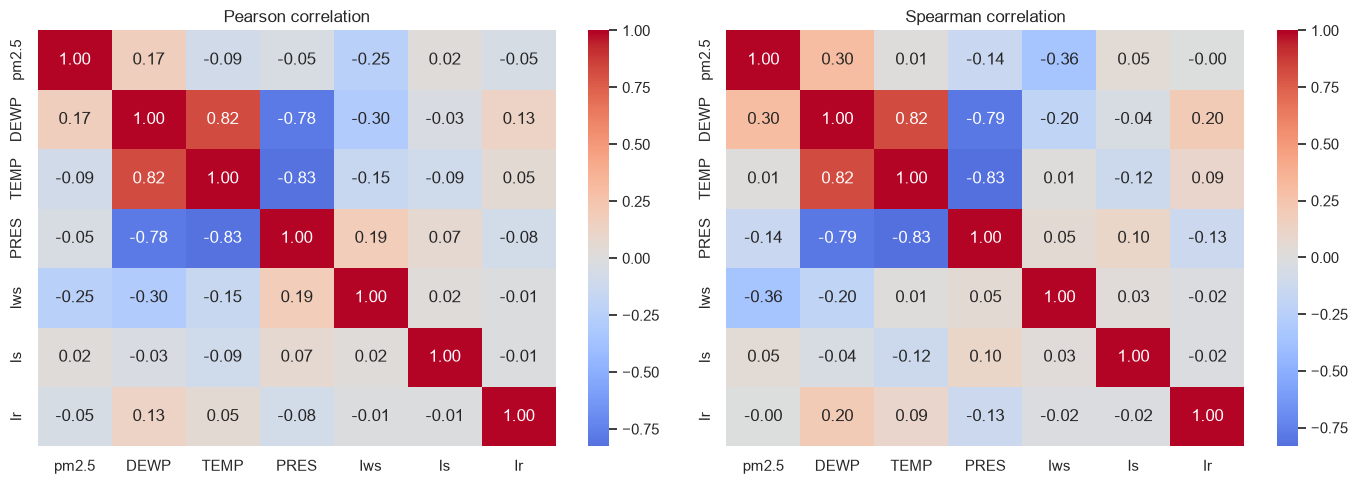

In [84]:
num_cols = ["pm2.5", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Pearson correlation")
sns.heatmap(df[num_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Spearman correlation")
plt.tight_layout()
plt.show()

### 1.4 Datetime index and timestamp checks

In [85]:
# Combine the 4 date/time columns into one datetime index
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.set_index("datetime").sort_index()
df = df.drop(columns=["No"])   # row counter, carries no information

# Every hour should appear exactly once
print("Duplicated timestamps:", df.index.duplicated().sum())
full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("Missing timestamps:", len(full_range.difference(df.index)))
print("Date range:", df.index.min(), "->", df.index.max())

Duplicated timestamps: 0
Missing timestamps: 0
Date range: 2010-01-01 00:00:00 -> 2014-12-31 23:00:00


### 1.5 Locating the gaps in PM2.5

In [86]:
def run_lengths(mask):
    """For every row, the length of the run of identical values it belongs to."""
    run_id = (mask != mask.shift()).cumsum()
    return mask.groupby(run_id).transform("size")

is_na = df["pm2.5"].isna()
run_id = (is_na != is_na.shift()).cumsum()
gaps = (
    df[is_na]
    .groupby(run_id[is_na])
    .apply(lambda g: pd.Series({"start": g.index[0], "length_h": len(g)}))
)

print("Number of gaps:", len(gaps))
print("Missing hours:", is_na.sum(), f"({is_na.mean():.1%})")

print("\nGap length summary:")
print(pd.cut(gaps["length_h"], [0, 1, 3, 6, 24, 72, 1000],
             labels=["1h", "2-3h", "4-6h", "7-24h", "25-72h", ">72h"]).value_counts().sort_index())

print("\nMissing hours per year:")
print(is_na.groupby(df.index.year).sum())

print("\nLongest gaps:")
print(gaps.sort_values("length_h", ascending=False).head(10))

Number of gaps: 214
Missing hours: 2067 (4.7%)

Gap length summary:
length_h
1h        112
2-3h       31
4-6h       15
7-24h      36
25-72h     13
>72h        7
Name: count, dtype: int64

Missing hours per year:
datetime
2010    669
2011    728
2012    489
2013     82
2014     99
Name: pm2.5, dtype: int64

Longest gaps:
                    start  length_h
pm2.5                              
41    2010-09-21 05:00:00       155
287   2012-12-23 06:00:00       127
163   2011-10-03 13:00:00        99
61    2011-03-17 21:00:00        91
43    2010-09-27 17:00:00        76
185   2012-01-14 10:00:00        74
259   2012-08-18 11:00:00        74
27    2010-06-04 12:00:00        72
35    2010-08-13 20:00:00        68
3     2010-01-23 17:00:00        67


### 1.6 Impossible values and stuck sensors

In [87]:
print("PM2.5 == 0 :", (df["pm2.5"] == 0).sum())
print("DEWP > TEMP:", (df["DEWP"] > df["TEMP"]).sum())
print("Iws <= 0   :", (df["Iws"] <= 0).sum())

# Longest run where a column repeats the exact same value
for col in ["pm2.5", "TEMP", "DEWP", "PRES"]:
    s = df[col]
    lengths = s.groupby((s != s.shift()).cumsum()).transform("size")
    lengths = lengths[s.notna()]
    print(f"{col:6s} longest repeat: {lengths.max():3d}h  starting {lengths.idxmax()}")

# Hours where all three weather readings are stuck together for 24h or more
frozen = (df["TEMP"].diff() == 0) & (df["DEWP"].diff() == 0) & (df["PRES"].diff() == 0)
frozen_block = frozen & (run_lengths(frozen) >= 24)
print("\nFrozen weather hours (TEMP+DEWP+PRES stuck >= 24h):", frozen_block.sum())
print(frozen_block[frozen_block].groupby(frozen_block[frozen_block].index.date).size())

PM2.5 == 0 : 2
DEWP > TEMP: 1
Iws <= 0   : 0
pm2.5  longest repeat:   4h  starting 2010-01-29 11:00:00
TEMP   longest repeat:  49h  starting 2012-10-11 23:00:00
DEWP   longest repeat:  49h  starting 2012-10-13 23:00:00
PRES   longest repeat:  48h  starting 2012-10-11 23:00:00

Frozen weather hours (TEMP+DEWP+PRES stuck >= 24h): 167
2010-11-13     3
2010-11-14    24
2010-11-15    21
2010-11-16    24
2010-11-17     2
2012-10-12    24
2012-10-13    23
2012-10-14    23
2012-10-15    23
dtype: int64


### 1.7 Outliers: errors or real events?

datetime
2012-01-23 01:00:00    994.0
2010-02-14 01:00:00    980.0
2012-01-23 02:00:00    972.0
2013-01-12 20:00:00    886.0
2013-01-12 22:00:00    858.0
Name: pm2.5, dtype: float64

Around 2012-01-23 01:00:00
                     pm2.5 cbwd    Iws  TEMP
datetime                                    
2012-01-22 21:00:00  193.0   cv   0.89 -10.0
2012-01-22 22:00:00  182.0   NW   1.79 -14.0
2012-01-22 23:00:00  161.0   cv   0.89 -11.0
2012-01-23 00:00:00  225.0   NW   3.13 -11.0
2012-01-23 01:00:00  994.0   NW   4.92 -12.0
2012-01-23 02:00:00  972.0   NW   8.05 -12.0
2012-01-23 03:00:00  430.0   NW  11.18 -14.0
2012-01-23 04:00:00  296.0   cv   0.89 -15.0
2012-01-23 05:00:00  284.0   NW   1.79 -15.0

Around 2010-02-14 01:00:00
                     pm2.5 cbwd    Iws  TEMP
datetime                                    
2010-02-13 21:00:00  213.0   cv   0.89  -4.0
2010-02-13 22:00:00  259.0   cv   1.78  -5.0
2010-02-13 23:00:00  267.0   cv   2.67  -6.0
2010-02-14 00:00:00  351.0   NE   0.89  -7

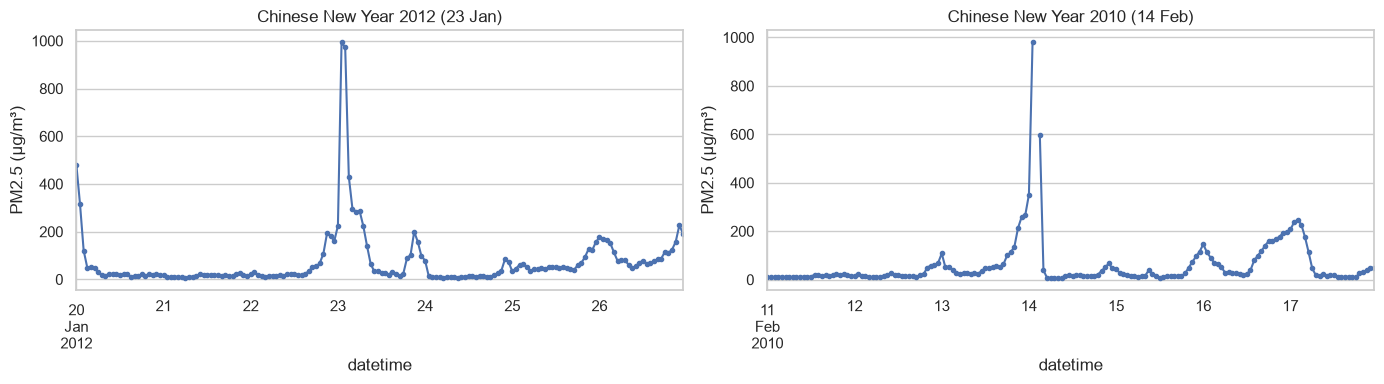

In [88]:
top = df["pm2.5"].nlargest(5)
print(top)

for ts in top.index[:2]:
    print("\nAround", ts)
    print(df.loc[ts - pd.Timedelta(hours=4): ts + pd.Timedelta(hours=4),
                 ["pm2.5", "cbwd", "Iws", "TEMP"]])

print("\nHours above 500:", (df["pm2.5"] > 500).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df.loc["2012-01-20":"2012-01-26", "pm2.5"].plot(ax=axes[0], marker=".")
axes[0].set_title("Chinese New Year 2012 (23 Jan)")
df.loc["2010-02-11":"2010-02-17", "pm2.5"].plot(ax=axes[1], marker=".")
axes[1].set_title("Chinese New Year 2010 (14 Feb)")
for ax in axes:
    ax.set_ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

### 1.8 Cleaning: fixing the sensor and filling or dropping gaps

In [89]:
clean = df.copy()

# 1) broken weather sensor -> NaN -> interpolate over time
clean.loc[frozen_block, ["TEMP", "DEWP", "PRES"]] = np.nan
clean[["TEMP", "DEWP", "PRES"]] = clean[["TEMP", "DEWP", "PRES"]].interpolate(method="time")

# 2) dew point can't be above temperature
clean["DEWP"] = clean["DEWP"].clip(upper=clean["TEMP"])

# 3) PM2.5 of exactly 0 is a glitch -> missing
clean.loc[clean["pm2.5"] == 0, "pm2.5"] = np.nan

# 4) short gaps -> interpolate, long gaps -> drop
MAX_GAP = 24  # hours
is_na = clean["pm2.5"].isna()
gap_len = run_lengths(is_na)
short_gap = is_na & (gap_len <= MAX_GAP)
long_gap = is_na & (gap_len > MAX_GAP)

filled = clean["pm2.5"].interpolate(method="time", limit_area="inside")
clean.loc[short_gap, "pm2.5"] = filled[short_gap]
clean["was_missing"] = short_gap.astype(int)

print("Filled (short gaps):", short_gap.sum())
print("Dropped (long gaps):", long_gap.sum())

clean = clean.dropna(subset=["pm2.5"])
print("Rows before:", len(df), "| after:", len(clean), f"| kept {len(clean)/len(df):.1%}")
print("Missing values left:", clean.isna().sum().sum())

Filled (short gaps): 728
Dropped (long gaps): 1341
Rows before: 43824 | after: 42459 | kept 96.9%
Missing values left: 0


## Part 1 summary: understanding and cleaning the data

**What the data looks like**
- 43,824 hourly rows (Jan 2010 to Dec 2014), 13 columns. Only `pm2.5` has missing values (2,067 hours, 4.7%).
- No duplicated rows. After building the datetime index there are no duplicated or missing timestamps, so the series is perfectly hourly.
- `pm2.5` is heavily right-skewed (median 72, mean 98.6, max 994).
- `Iws`, `Is` and `Ir` are cumulative (they keep counting while the same wind or weather continues), and `Is` and `Ir` are mostly zeros.
- Correlations with `pm2.5` are weak on their own (strongest: `Iws` negative, `DEWP` positive), and Spearman is stronger than Pearson, so the relationships are non-linear.

**Datetime index.** The four date columns were combined into one index and `No` was dropped. A time index is needed for time plots, interpolation by time, lag features and splitting by date. `No` is only a row counter.

**Missing values: where.** The 2,067 missing hours form 214 gaps. Most are tiny (112 single hours), but 20 last more than a day, and the longest is 155 hours. Most of the missing data falls in 2010–2012.

**Missing values: treatment.**
- Short gaps (≤ 24 h) were interpolated over time (728 hours). PM2.5 changes slowly hour to hour (lag-1 autocorrelation ≈ 0.97), so the neighbours give a close estimate.
- Long gaps (> 24 h) were dropped (1,341 hours). Interpolating across days would invent fake smooth stretches.
- The overall mean (≈ 99) was not used. It ignores time, so it would put the same value into a clean windy night and into a smog episode, which erases the daily and seasonal patterns.
- A `was_missing` flag records which values were filled.

**Impossible values / broken sensor.**
- `pm2.5 = 0` appears twice, and these were treated as missing (real city air is never perfectly clean).
- One hour has dew point above temperature, which is impossible, so `DEWP` was clipped to `TEMP`.
- The PM2.5 sensor looks healthy (no value repeats for more than 4 h).
- TEMP, DEWP and PRES are all frozen together for 24 h or more in Nov 2010 and Oct 2012 (167 hours), which is a logging fault. Those hours were set to missing and interpolated.

**Outliers.** The highest readings (994 on 23 Jan 2012 and 980 on 14 Feb 2010) are both on Chinese New Year night, when fireworks go off. They build up over the evening and fall within hours when the NW wind arrives, which is how a real event looks. There are 125 hours above 500, and they come in multi-hour episodes. The spikes were kept, because they're exactly what a health alert must catch. The skew will be handled with a log transform later.

**Result:** 42,459 clean rows (96.9%) with no missing values. From here on `clean` is used, and `df` stays as the raw copy.

# 2. Exploring and Visualizing the Data

### 2.0 Plot setup 

In [90]:
import os
os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid")

def save(fig, name):
    """Save a figure into the figures/ folder (used later in the README)."""
    fig.savefig(f"figures/{name}.png", dpi=120, bbox_inches="tight")

### 2.1 PM2.5 distribution and skewness

Skewness raw: 1.81 | after log1p: -0.30


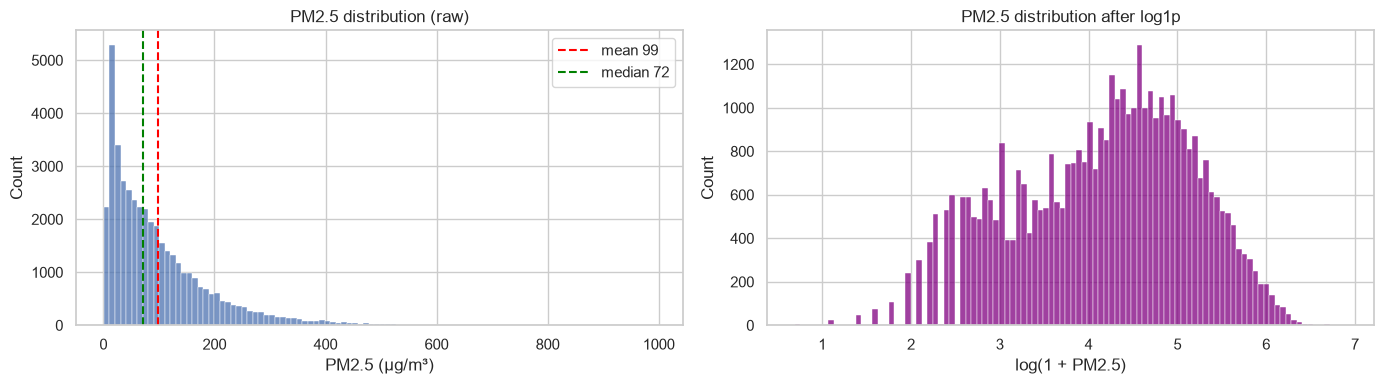

In [91]:
pm = clean["pm2.5"]
print(f"Skewness raw: {pm.skew():.2f} | after log1p: {np.log1p(pm).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(pm, bins=100, ax=axes[0])
axes[0].axvline(pm.mean(), color="red", ls="--", label=f"mean {pm.mean():.0f}")
axes[0].axvline(pm.median(), color="green", ls="--", label=f"median {pm.median():.0f}")
axes[0].set_title("PM2.5 distribution (raw)")
axes[0].set_xlabel("PM2.5 (µg/m³)")
axes[0].legend()
sns.histplot(np.log1p(pm), bins=100, ax=axes[1], color="purple")
axes[1].set_title("PM2.5 distribution after log1p")
axes[1].set_xlabel("log(1 + PM2.5)")
plt.tight_layout()
save(fig, "01_pm25_distribution")
plt.show()

### 2.2 Boxplots and outlier counts for every numeric column

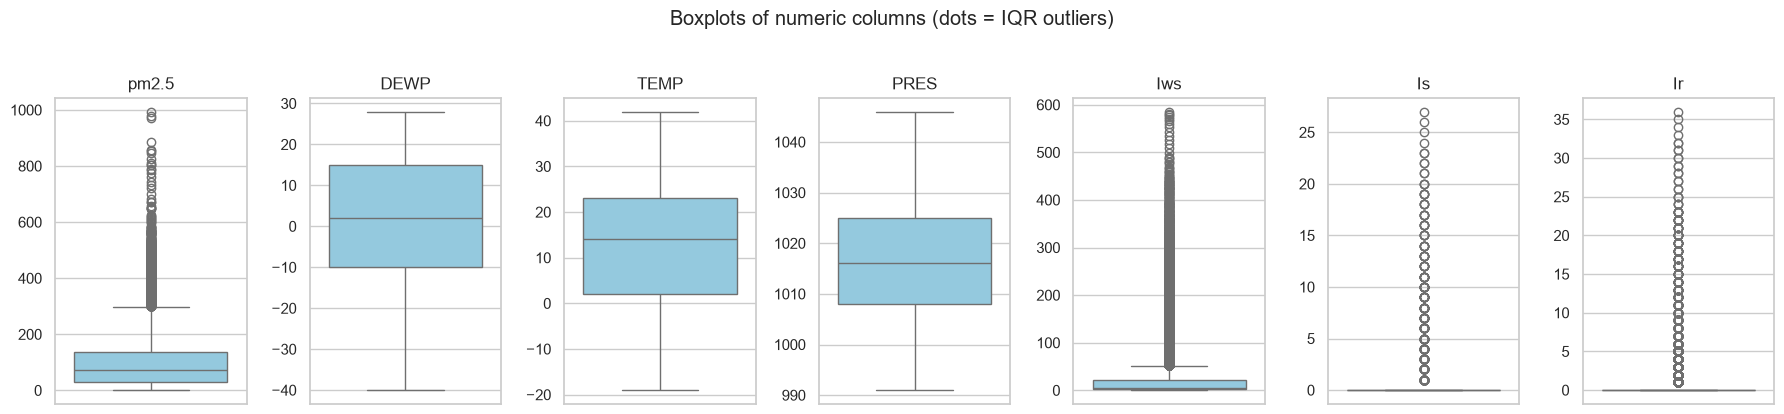

pm2.5  IQR outliers:  1796 (4.2%) | zeros: 0.0%
DEWP   IQR outliers:     0 (0.0%) | zeros: 1.9%
TEMP   IQR outliers:     0 (0.0%) | zeros: 2.6%
PRES   IQR outliers:     0 (0.0%) | zeros: 0.0%
Iws    IQR outliers:  4945 (11.6%) | zeros: 0.0%
Is     IQR outliers:   368 (0.9%) | zeros: 99.1%
Ir     IQR outliers:  1774 (4.2%) | zeros: 95.8%


In [92]:
num_cols = ["pm2.5", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=clean[col], ax=ax, color="skyblue")
    ax.set_title(col)
    ax.set_ylabel("")
plt.suptitle("Boxplots of numeric columns (dots = IQR outliers)", y=1.03)
plt.tight_layout()
save(fig, "02_boxplots")
plt.show()

for col in num_cols:
    q1, q3 = clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((clean[col] < q1 - 1.5 * iqr) | (clean[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:6s} IQR outliers: {n_out:5d} ({n_out / len(clean):.1%}) | zeros: {(clean[col] == 0).mean():.1%}")

### 2.3 PM2.5 over time (2010-2014)

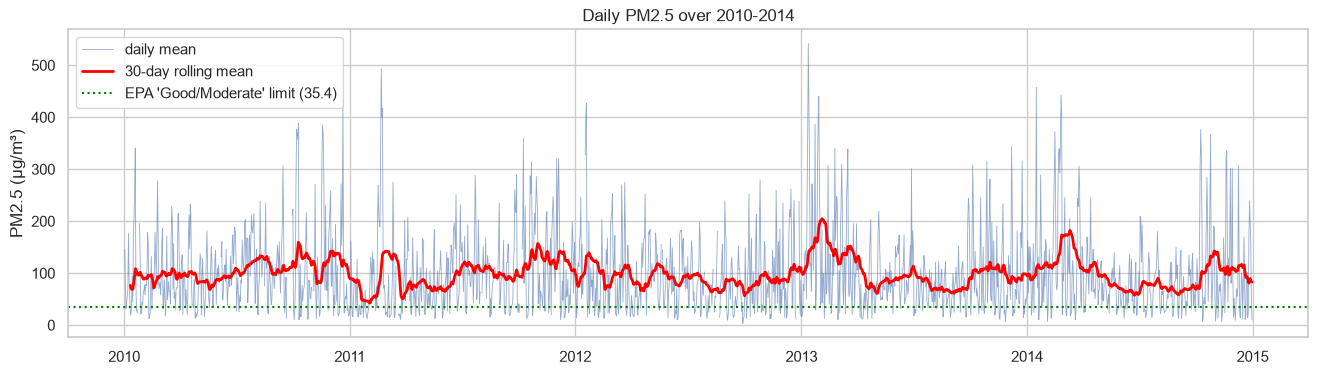

In [93]:
daily = clean["pm2.5"].resample("D").mean()
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(daily.index, daily, lw=0.6, alpha=0.6, label="daily mean")
ax.plot(daily.index, daily.rolling(30, min_periods=10).mean(), color="red", lw=2, label="30-day rolling mean")
ax.axhline(35.4, color="green", ls=":", label="EPA 'Good/Moderate' limit (35.4)")
ax.set_title("Daily PM2.5 over 2010-2014")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
save(fig, "03_time_series")
plt.show()

### 2.4 Daily cycle: PM2.5 by hour of day

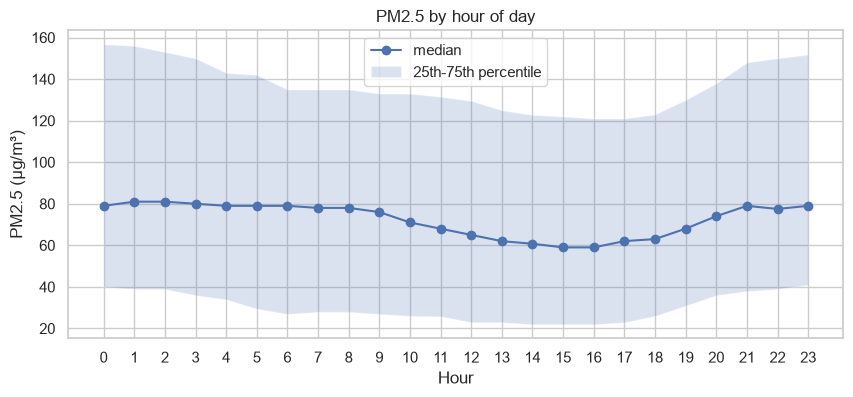

In [94]:
by_hour = clean.groupby(clean.index.hour)["pm2.5"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_hour.median(), marker="o", label="median")
ax.fill_between(range(24), by_hour.quantile(0.25), by_hour.quantile(0.75), alpha=0.2, label="25th-75th percentile")
ax.set_xticks(range(24))
ax.set_title("PM2.5 by hour of day")
ax.set_xlabel("Hour")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
save(fig, "04_hour_profile")
plt.show()

### 2.5 Seasonality: PM2.5 by month

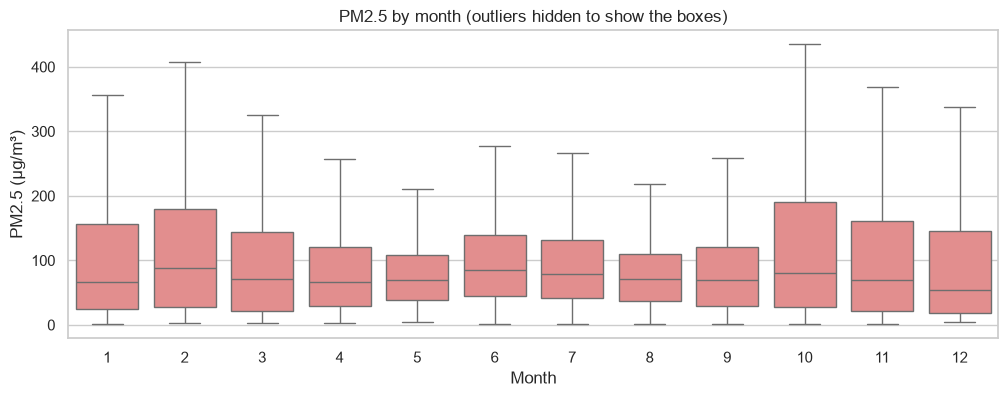

Share of hours above 150 µg/m³ by month:
datetime
1     0.27
2     0.31
3     0.23
4     0.17
5     0.10
6     0.20
7     0.19
8     0.11
9     0.15
10    0.32
11    0.27
12    0.24
Name: pm2.5, dtype: float64


In [95]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(x=clean.index.month, y=clean["pm2.5"], ax=ax, color="lightcoral", showfliers=False)
ax.set_title("PM2.5 by month (outliers hidden to show the boxes)")
ax.set_xlabel("Month")
ax.set_ylabel("PM2.5 (µg/m³)")
save(fig, "05_month_boxplot")
plt.show()

print("Share of hours above 150 µg/m³ by month:")
print((clean["pm2.5"] > 150).groupby(clean.index.month).mean().round(2))

### 2.6 Hour x month heatmap

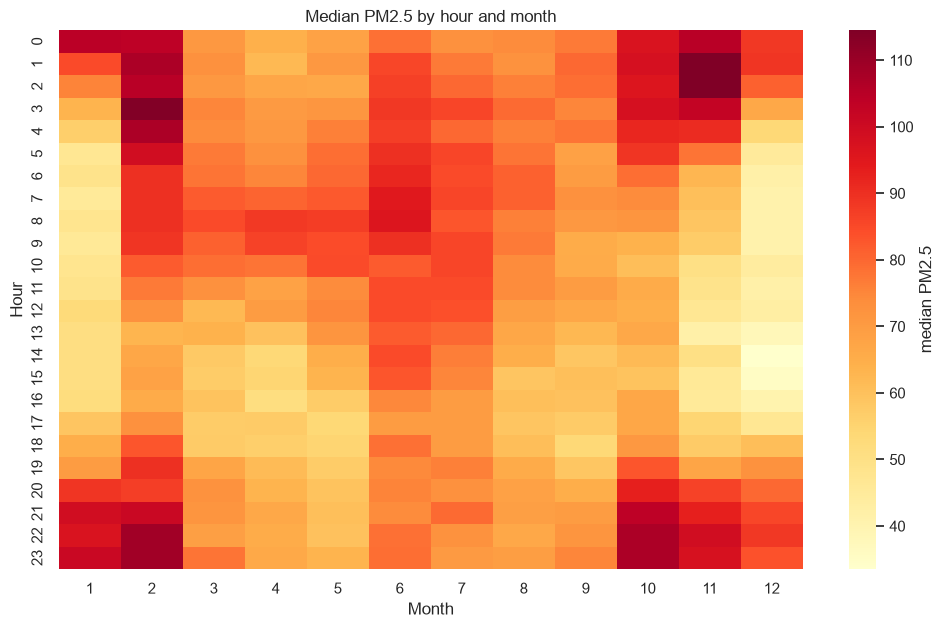

In [96]:
pivot = clean.pivot_table(values="pm2.5", index=clean.index.hour, columns=clean.index.month, aggfunc="median")
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(pivot, cmap="YlOrRd", ax=ax, cbar_kws={"label": "median PM2.5"})
ax.set_title("Median PM2.5 by hour and month")
ax.set_xlabel("Month")
ax.set_ylabel("Hour")
save(fig, "06_hour_month_heatmap")
plt.show()

### 2.7 PM2.5 by wind direction

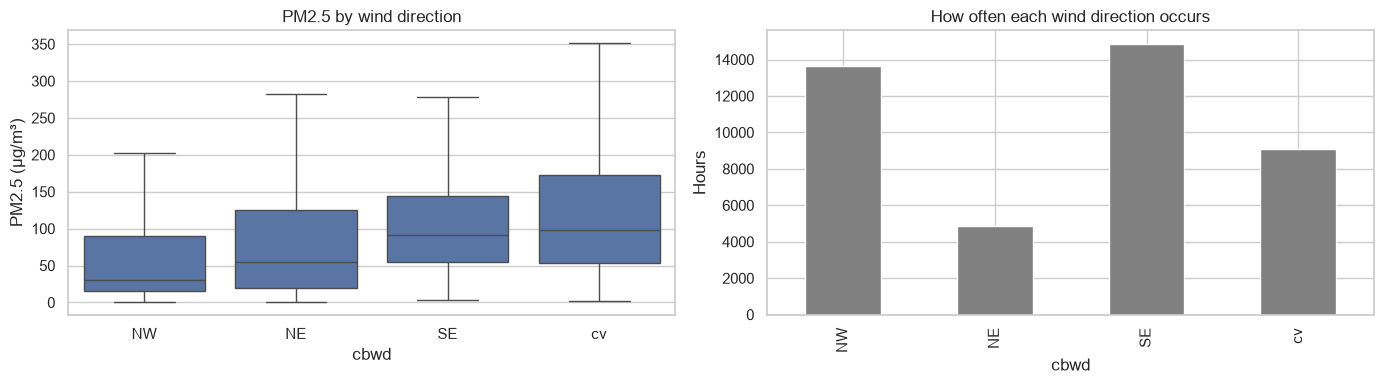

cbwd
NW    31.0
NE    55.0
SE    91.0
cv    98.0
Name: pm2.5, dtype: float64


In [97]:
order = ["NW", "NE", "SE", "cv"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=clean, x="cbwd", y="pm2.5", order=order, ax=axes[0], showfliers=False)
axes[0].set_title("PM2.5 by wind direction")
axes[0].set_ylabel("PM2.5 (µg/m³)")
clean["cbwd"].value_counts().reindex(order).plot.bar(ax=axes[1], color="gray")
axes[1].set_title("How often each wind direction occurs")
axes[1].set_ylabel("Hours")
plt.tight_layout()
save(fig, "07_wind_direction")
plt.show()

print(clean.groupby("cbwd")["pm2.5"].median().reindex(order))

### 2.8 PM2.5 vs wind speed

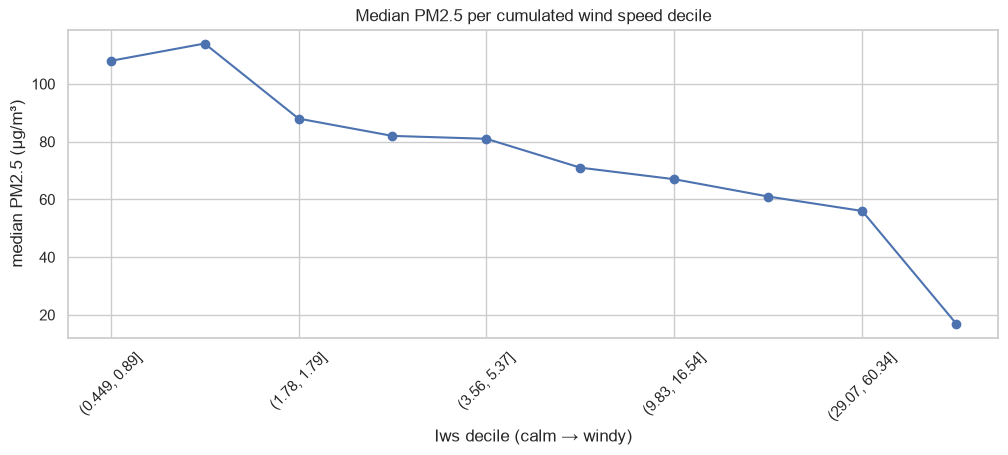

In [98]:
iws_bins = pd.qcut(clean["Iws"], 10)
fig, ax = plt.subplots(figsize=(12, 4))
clean.groupby(iws_bins, observed=True)["pm2.5"].median().plot(ax=ax, marker="o")
ax.set_title("Median PM2.5 per cumulated wind speed decile")
ax.set_xlabel("Iws decile (calm → windy)")
ax.set_ylabel("median PM2.5 (µg/m³)")
ax.tick_params(axis="x", rotation=45)
save(fig, "08_wind_speed")
plt.show()

### 2.9 Humidity: dew-point spread vs PM2.5

Spearman corr PM2.5 vs TEMP:  0.01
Spearman corr PM2.5 vs DEWP:  0.30
Spearman corr PM2.5 vs TEMP-DEWP: -0.52


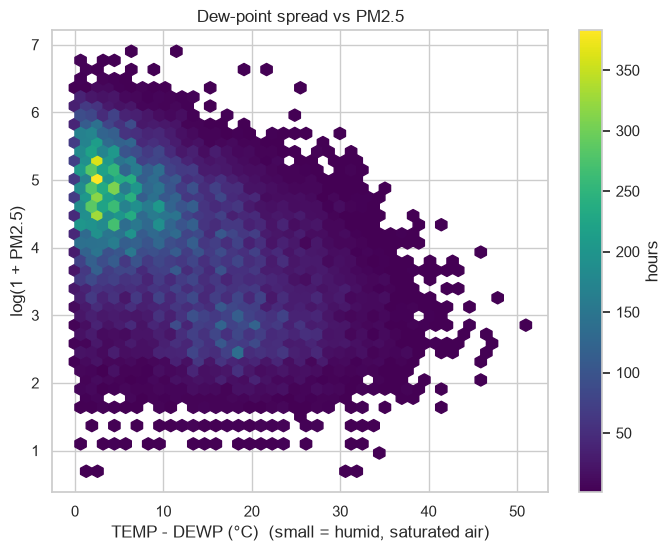

In [99]:
spread = clean["TEMP"] - clean["DEWP"]
print(f"Spearman corr PM2.5 vs TEMP:  {clean['pm2.5'].corr(clean['TEMP'], method='spearman'):.2f}")
print(f"Spearman corr PM2.5 vs DEWP:  {clean['pm2.5'].corr(clean['DEWP'], method='spearman'):.2f}")
print(f"Spearman corr PM2.5 vs TEMP-DEWP: {clean['pm2.5'].corr(spread, method='spearman'):.2f}")

fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(spread, np.log1p(clean["pm2.5"]), gridsize=40, cmap="viridis", mincnt=1)
fig.colorbar(hb, ax=ax, label="hours")
ax.set_title("Dew-point spread vs PM2.5")
ax.set_xlabel("TEMP - DEWP (°C)  (small = humid, saturated air)")
ax.set_ylabel("log(1 + PM2.5)")
save(fig, "09_dewpoint_spread")
plt.show()

### 2.10 Autocorrelation: how much the past predicts the present

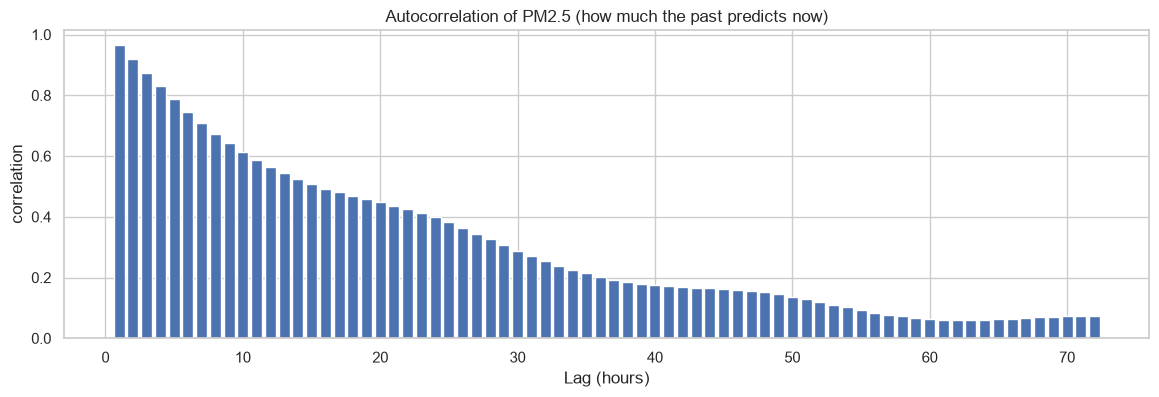

{1: np.float64(0.966), 2: np.float64(0.919), 3: np.float64(0.873), 6: np.float64(0.746), 12: np.float64(0.564), 24: np.float64(0.398), 48: np.float64(0.152)}


In [100]:
# asfreq("h") puts the dropped hours back as NaN so a shift of 1 is always exactly 1 hour
pm_hourly = clean["pm2.5"].asfreq("h")
lags = range(1, 73)
acf = [pm_hourly.autocorr(l) for l in lags]
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(lags, acf)
ax.set_title("Autocorrelation of PM2.5 (how much the past predicts now)")
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("correlation")
save(fig, "10_autocorrelation")
plt.show()

print({l: round(pm_hourly.autocorr(l), 3) for l in [1, 2, 3, 6, 12, 24, 48]})

### 2.11 PM2.5 now vs one hour earlier

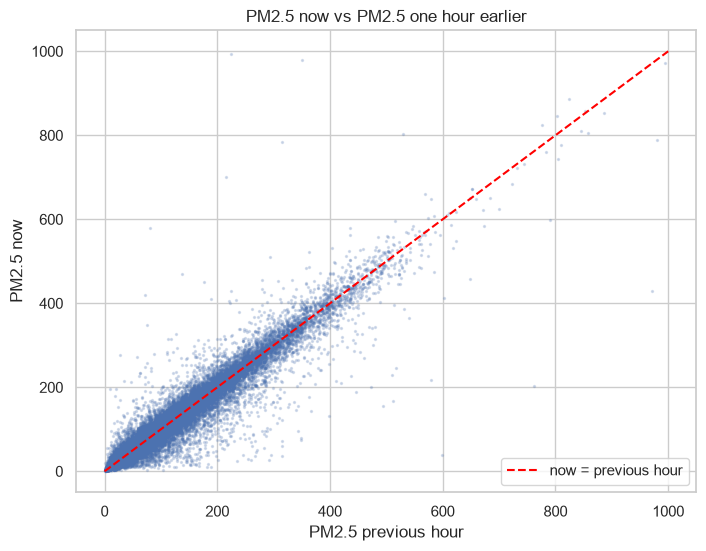

In [101]:
fig, ax = plt.subplots(figsize=(8, 6))
lag_df = pd.DataFrame({"now": pm_hourly, "prev": pm_hourly.shift(1)}).dropna()
ax.scatter(lag_df["prev"], lag_df["now"], s=2, alpha=0.2)
ax.plot([0, 1000], [0, 1000], color="red", ls="--", label="now = previous hour")
ax.set_title("PM2.5 now vs PM2.5 one hour earlier")
ax.set_xlabel("PM2.5 previous hour")
ax.set_ylabel("PM2.5 now")
ax.legend()
save(fig, "11_lag1_scatter")
plt.show()

## Part 2 summary: exploring and visualizing

| Plot | What it shows | Insight | What it changes next |
|---|---|---|---|
| 2.1 Distribution | PM2.5 histogram raw vs log | Strong right skew (1.81): most hours are moderate, with a long tail up to ~1000. After `log1p` the skew is −0.30, almost symmetric. | Regression will predict `log1p(PM2.5)`, and results get converted back to µg/m³. |
| 2.2 Boxplots | Spread and IQR outliers of each column | PM2.5 has ~4% IQR "outliers", but Part 1 showed they are real events. `Iws` has 11.6% outliers because it is cumulative. `Is`/`Ir` are 99% / 96% zeros. | Keep the spikes and use a robust scaler. Log-transform `Iws`. Turn `Is`/`Ir` into 0/1 flags. |
| 2.3 Time series | Daily mean 2010–2014 plus a 30-day trend | Clear yearly cycle with winter peaks, no long-term upward or downward trend, and about 79% of days above the EPA "good" limit (35.4). | Seasonal features (month) matter. Because there's no trend, a split by year (test = 2014) is fair. |
| 2.4 Hour of day | Median PM2.5 per hour | Highest at night (~80 around midnight), lowest in the afternoon (~58 at 15:00), because the mixing layer is deep in the afternoon and shallow at night. | Add the hour as a cyclical feature (sin/cos) so 23:00 and 00:00 are neighbours. |
| 2.5 Month | Boxplots per month and the share of hours above 150 | Medians are similar all year, but the bad tail is much worse in the heating season: 31–32% of hours above 150 in Feb/Oct against 10–11% in May/Aug. | The month matters mostly for extreme hours, which is important for the "Very Unhealthy" class. Add the month as a cyclical feature. |
| 2.6 Hour × month heatmap | Median PM2.5 for every hour–month combination | The daily cycle is strongest in winter: winter nights are the worst hours of the year (>100), while December afternoons are among the cleanest. | Hour and month interact, so non-linear models (RBF kernel) should help over a purely linear model. |
| 2.7 Wind direction | PM2.5 per `cbwd` and how often each occurs | NW (cold, dry air from the north) is cleanest (median 31), then NE 55, SE 91, and calm is worst (98). | `cbwd` is a strong categorical feature → one-hot encode it. |
| 2.8 Wind speed | Median PM2.5 per `Iws` decile | Monotonic drop from ~110 in calm hours to ~17 in the windiest 10%. The relationship is strong but not a straight line. | Keep `Iws`, log-transform it to compress the long tail. |
| 2.9 Dew-point spread | TEMP − DEWP vs log PM2.5 | The spread correlates −0.52 (Spearman), far stronger than TEMP (0.01) or DEWP (0.30) alone. Humid, near-saturated air traps pollution. | Engineer `TEMP − DEWP` as a new feature. |
| 2.10 Autocorrelation | Correlation of PM2.5 with itself 1–72 h earlier | 0.965 at 1 h, 0.87 at 3 h, 0.39 at 24 h, near 0 after 2 days. Pollution builds up and clears over hours to days. | Create lag features (1, 2, 3, 6, 24 h) and rolling means. Use a time-based split, because a random split would leak neighbouring hours. |
| 2.11 Lag-1 scatter | PM2.5 now vs one hour earlier | Points hug the diagonal, and the spread widens at high values (sudden spikes and clean-ups). | "Previous hour" is a very strong baseline that the models must beat, and large errors will concentrate on spikes. |

# 3. Feature Engineering and Preprocessing

### 3.1 Restore the full hourly timeline

In [102]:
# Put the dropped hours back as empty rows so every shift/rolling step is exactly 1 hour
data = clean.asfreq("h")
print("Rows on the full hourly timeline:", len(data), "| rows with PM2.5:", data["pm2.5"].notna().sum())

Rows on the full hourly timeline: 43800 | rows with PM2.5: 42459


### 3.2 Log-transform the target

In [103]:
# Target for regression: log1p(PM2.5), undone later with np.expm1
data["pm25_log"] = np.log1p(data["pm2.5"])
print(f"Skew raw: {data['pm2.5'].skew():.2f} | Skew log1p: {data['pm25_log'].skew():.2f}")

Skew raw: 1.81 | Skew log1p: -0.30


### 3.3 Cyclical time features

In [104]:
# Cyclical time features: sin/cos puts 23:00 next to 00:00 and December next to January
hour = data.index.hour
month = data.index.month
data["hour_sin"] = np.sin(2 * np.pi * hour / 24)
data["hour_cos"] = np.cos(2 * np.pi * hour / 24)
data["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
data["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12)
data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

data[["hour_sin", "hour_cos", "month_sin", "month_cos", "is_weekend"]].head(3)

,hour_sin,hour_cos,month_sin,month_cos,is_weekend
datetime,,,,,
2010-01-02 00:00:00,0.000000,1.000000,0.0,1.0,1
2010-01-02 01:00:00,0.258819,0.965926,0.0,1.0,1
2010-01-02 02:00:00,0.500000,0.866025,0.0,1.0,1


### 3.4 Weather features from the EDA

In [105]:
# Weather features suggested by the EDA
data["dew_spread"] = data["TEMP"] - data["DEWP"]     # small spread = humid, stagnant air
data["log_Iws"] = np.log1p(data["Iws"])              # compress the long tail of cumulated wind
data["is_rain"] = (data["Ir"] > 0).astype(int)       # Ir / Is are ~96-99% zeros -> 0/1 flags
data["is_snow"] = (data["Is"] > 0).astype(int)

for col in ["Iws", "log_Iws", "dew_spread"]:
    print(f"{col:10s} skew: {data[col].skew():5.2f} | Spearman with PM2.5: "
          f"{data[col].corr(data['pm2.5'], method='spearman'):5.2f}")

Iws        skew:  4.31 | Spearman with PM2.5: -0.36
log_Iws    skew:  0.70 | Spearman with PM2.5: -0.36
dew_spread skew:  0.83 | Spearman with PM2.5: -0.52


### 3.5 log1p vs Yeo-Johnson for wind speed

In [106]:
# Compare log1p vs Yeo-Johnson for the most skewed feature (Iws)
from sklearn.preprocessing import PowerTransformer

iws = data[["Iws"]].dropna()
yj = PowerTransformer(method="yeo-johnson").fit(iws)
print(f"Iws skew  raw: {iws['Iws'].skew():.2f}")
print(f"          log1p: {np.log1p(iws['Iws']).skew():.2f}")
print(f"          Yeo-Johnson: {pd.Series(yj.transform(iws).ravel()).skew():.2f} (lambda = {yj.lambdas_[0]:.2f})")

Iws skew  raw: 4.31
          log1p: 0.70
          Yeo-Johnson: 0.16 (lambda = -0.29)


### 3.6 Lag and rolling features (past values only)

In [107]:
# Lag and rolling features: ONLY past values (shift(1) before rolling), so no future leaks in.
# They are built on log1p(PM2.5): the target is on the log scale, so log lags relate to it in a
# straight line, which Linear Regression needs.
lpm = data["pm25_log"]
for lag in [1, 2, 3, 6, 12, 24]:
    data[f"pm_lag{lag}"] = lpm.shift(lag)

past = lpm.shift(1)
data["pm_roll3_mean"] = past.rolling(3).mean()
data["pm_roll24_mean"] = past.rolling(24).mean()
data["pm_roll24_std"] = past.rolling(24).std()
data["pm_diff1"] = lpm.shift(1) - lpm.shift(2)          # was PM2.5 rising or falling last hour?

# Past weather too: wind in the previous hours clears or builds pollution
data["log_Iws_lag1"] = data["log_Iws"].shift(1)
data["wind_changed"] = (data["cbwd"] != data["cbwd"].shift(1)).astype(int)

# Sanity check: lag1 must equal the previous hour's value
check = data[["pm25_log", "pm_lag1"]].dropna().head(4)
print(check)

                     pm25_log   pm_lag1
datetime                               
2010-01-02 01:00:00  5.003946  4.867534
2010-01-02 02:00:00  5.075174  5.003946
2010-01-02 03:00:00  5.204007  5.075174
2010-01-02 04:00:00  4.934474  5.204007


### 3.7 Feature list and usable rows

In [108]:
# Drop rows that are not usable: no target (long gaps) or missing lags (first day, right after long gaps)
feature_cols = [
    # weather
    "DEWP", "TEMP", "PRES", "dew_spread", "log_Iws", "log_Iws_lag1", "is_rain", "is_snow",
    "wind_changed", "cbwd",
    # time
    "hour_sin", "hour_cos", "month_sin", "month_cos", "is_weekend",
    # past PM2.5
    "pm_lag1", "pm_lag2", "pm_lag3", "pm_lag6", "pm_lag12", "pm_lag24",
    "pm_roll3_mean", "pm_roll24_mean", "pm_roll24_std", "pm_diff1",
]

model_df = data.dropna(subset=feature_cols + ["pm2.5"]).copy()
print("Rows before:", clean.shape[0], "| usable rows:", model_df.shape[0])
print("Number of features:", len(feature_cols))

Rows before: 42459 | usable rows: 41986
Number of features: 25


### 3.8 Time-based train/test split

In [109]:
# Time-based split: train on the past, test on the future (never shuffle a time series)
train = model_df.loc[:"2013-12-31"]
test = model_df.loc["2014-01-01":]

X_train, X_test = train[feature_cols], test[feature_cols]
y_train, y_test = train["pm25_log"], test["pm25_log"]          # log target for models
y_train_raw, y_test_raw = train["pm2.5"], test["pm2.5"]        # µg/m³ for reporting

print(f"Train: {train.index.min().date()} -> {train.index.max().date()}  ({len(train)} rows)")
print(f"Test : {test.index.min().date()} -> {test.index.max().date()}  ({len(test)} rows)")
print(f"Test share: {len(test) / len(model_df):.1%}")
print(f"PM2.5 median  train: {y_train_raw.median():.0f} | test: {y_test_raw.median():.0f}")

Train: 2010-01-03 -> 2013-12-31  (33226 rows)
Test : 2014-01-01 -> 2014-12-31  (8760 rows)
Test share: 20.9%
PM2.5 median  train: 72 | test: 72


### 3.9 Scaling and encoding with a ColumnTransformer

In [110]:
# Preprocessing: scale numeric columns, one-hot encode wind direction, leave 0/1 and sin/cos as they are
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_features = ["DEWP", "TEMP", "PRES", "dew_spread", "log_Iws", "log_Iws_lag1",
                "pm_lag1", "pm_lag2", "pm_lag3", "pm_lag6", "pm_lag12", "pm_lag24",
                "pm_roll3_mean", "pm_roll24_mean", "pm_roll24_std", "pm_diff1"]
cat_features = ["cbwd"]
pass_features = ["is_rain", "is_snow", "wind_changed", "hour_sin", "hour_cos",
                 "month_sin", "month_cos", "is_weekend"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_features),
    ("pass", "passthrough", pass_features),
])

# Fit on TRAIN only, then apply the same transformation to test
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Shape after preprocessing  train:", X_train_prep.shape, "| test:", X_test_prep.shape)
print("Train means after scaling (should be ~0):", X_train_prep[:, :3].mean(axis=0).round(2))
print("Test  means after scaling (not exactly 0, that's expected):", X_test_prep[:, :3].mean(axis=0).round(2))
print(preprocessor.get_feature_names_out())

Shape after preprocessing  train: (33226, 27) | test: (8760, 27)
Train means after scaling (should be ~0): [ 0. -0.  0.]
Test  means after scaling (not exactly 0, that's expected): [0.03 0.13 0.03]
['num__DEWP' 'num__TEMP' 'num__PRES' 'num__dew_spread' 'num__log_Iws'
 'num__log_Iws_lag1' 'num__pm_lag1' 'num__pm_lag2' 'num__pm_lag3'
 'num__pm_lag6' 'num__pm_lag12' 'num__pm_lag24' 'num__pm_roll3_mean'
 'num__pm_roll24_mean' 'num__pm_roll24_std' 'num__pm_diff1' 'cat__cbwd_NW'
 'cat__cbwd_SE' 'cat__cbwd_cv' 'pass__is_rain' 'pass__is_snow'
 'pass__wind_changed' 'pass__hour_sin' 'pass__hour_cos' 'pass__month_sin'
 'pass__month_cos' 'pass__is_weekend']


### 3.10 Feature check: correlation with PM2.5

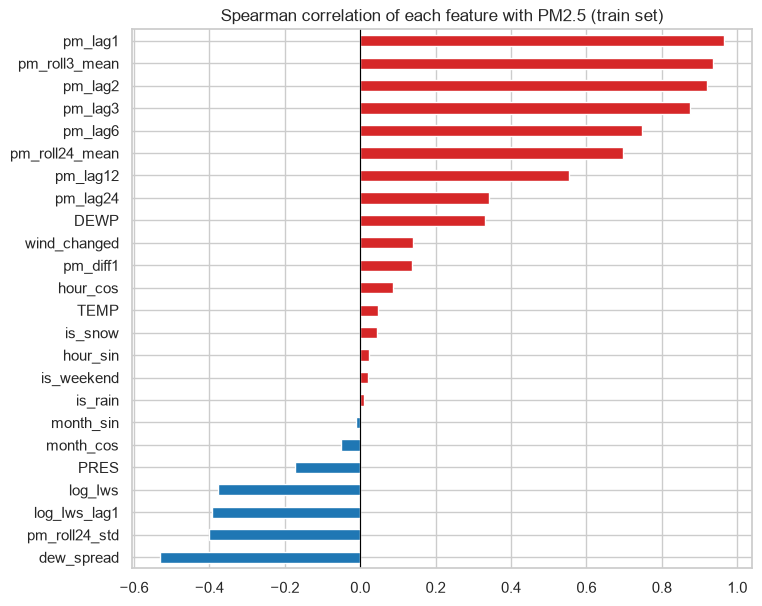

In [111]:
# Quick check: how strongly does each engineered feature relate to PM2.5 in the training set?
corr = (
    train[num_features + pass_features]
    .corrwith(train["pm2.5"], method="spearman")
    .sort_values()
)
fig, ax = plt.subplots(figsize=(8, 7))
corr.plot.barh(ax=ax, color=["tab:blue" if v < 0 else "tab:red" for v in corr])
ax.set_title("Spearman correlation of each feature with PM2.5 (train set)")
ax.axvline(0, color="black", lw=0.8)
save(fig, "12_feature_correlation")
plt.show()

## Part 3 summary: feature engineering and preprocessing

| Step | What was done | Why | What goes wrong without it |
|---|---|---|---|
| 3.1 Hourly timeline | `asfreq("h")` puts the hours dropped in Part 1 back as empty rows | Lags and rolling windows count **rows**. With holes in the index, "1 row back" could mean 3 days back. | Lag features would silently mix up hours across gaps, so the model learns from wrong "previous hours". |
| 3.2 Log target | `pm25_log = log1p(PM2.5)`, skew 1.81 → −0.30 | Errors on the log scale are relative (being 20 off at 30 is worse than 20 off at 400), and the models see a near-symmetric target. | The squared error would be dominated by a few extreme spikes, and Linear Regression would fit them badly and predict negative values for clean hours. |
| 3.3 Cyclical time | `sin`/`cos` of hour and month, plus a weekend flag | EDA showed strong daily and seasonal cycles. With sin/cos, 23:00 sits next to 00:00 and December next to January. | Raw `hour = 0…23` tells the model that 23:00 and 00:00 are as far apart as possible. |
| 3.4 Weather features | `dew_spread = TEMP − DEWP`, `log_Iws`, `is_rain`, `is_snow` | The spread is the strongest weather signal (Spearman −0.52). `log_Iws` cuts the skew from 4.31 to 0.70. `Is`/`Ir` are almost always 0, so a yes/no flag carries the useful information. | Weaker signal, and the extreme `Iws` values would dominate the scaler and any distance-based model (SVR). |
| 3.5 log vs Yeo-Johnson | Compared both on `Iws` | Yeo-Johnson reduces the skew more (0.16 vs 0.70), but log1p is simpler, needs no fitting, and already fixes most of it. | Either works. Yeo-Johnson must be fit on the training data only. |
| 3.6 Lags & rolling | PM2.5 (log) 1, 2, 3, 6, 12, 24 h back, 3 h and 24 h rolling mean, 24 h rolling std, last-hour change, previous-hour wind | Autocorrelation is 0.965 at 1 h and still 0.39 at 24 h, so the recent past is the strongest predictor. `shift(1)` **before** rolling makes sure only past hours are used. | Without lags the models lose their best information. Rolling without `shift(1)` would include the current hour, which leaks the answer. |
| 3.7 Usable rows | Rows without a target or with incomplete lags are dropped: 41,986 rows, 25 features | Models cannot handle NaN. | Crashes, or silently filled values that the model trusts. |
| 3.8 Time split | Train = 2010–2013 (33,226 rows), test = 2014 (8,760 rows, 21%) | This simulates real use: learn from the past, predict the future. Both sets have the same median (72). | A random split puts 10:00 in train and 11:00 in test. With lag features the model effectively sees the answer, and the scores look much better than they really are. |
| 3.9 Preprocessing | `StandardScaler` on numeric columns, `OneHotEncoder` on `cbwd`, sin/cos and 0/1 flags passed through. Fit on **train only**. | SVR/SVC and regularized Logistic Regression measure distances, so a feature in hPa (~1000) would outweigh one in °C. `cbwd` is text with no order. | Unscaled SVR is dominated by `PRES`. Label-encoding `cbwd` as 0–3 invents a fake order. Fitting the scaler on all data leaks test statistics into training. |
| 3.10 Feature check | Spearman correlation of every feature with PM2.5 on the train set | Confirms the engineered features carry signal: lag1 0.97, 24 h rolling mean 0.70, dew spread −0.53, log wind −0.38. | — |

**Which models need scaling?** SVR/SVC (distance and kernel based) and Logistic Regression with regularization do. Plain Linear Regression's predictions don't change with scaling, but its coefficients become comparable. Tree models wouldn't need it.

# 4. Regression: predicting hourly PM2.5

### 4.1 Regression setup: imports and scoring helper

In [112]:
# Regression imports and one helper to score every model the same way (always in µg/m³)
import time
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

reg_results = []

def score_regression(name, split, y_true_raw, y_pred_raw):
    """RMSE / MAE / R² in µg/m³, stored in reg_results for the comparison table."""
    row = {
        "model": name,
        "split": split,
        "RMSE": np.sqrt(mean_squared_error(y_true_raw, y_pred_raw)),
        "MAE": mean_absolute_error(y_true_raw, y_pred_raw),
        "R2": r2_score(y_true_raw, y_pred_raw),
    }
    reg_results.append(row)
    return row

def to_ugm3(pred_log):
    """Undo log1p and clip at 0 (PM2.5 can't be negative)."""
    return np.clip(np.expm1(pred_log), 0, None)

### 4.2 Baseline: PM2.5 = previous hour

In [113]:
# Baseline: "PM2.5 now = PM2.5 one hour ago". Any useful model must beat this.
base_train = to_ugm3(X_train["pm_lag1"])
base_test = to_ugm3(X_test["pm_lag1"])

print(score_regression("Baseline (previous hour)", "train", y_train_raw, base_train))
print(score_regression("Baseline (previous hour)", "test", y_test_raw, base_test))

{'model': 'Baseline (previous hour)', 'split': 'train', 'RMSE': np.float64(24.648979665696153), 'MAE': 12.954567039199556, 'R2': 0.9273668564923243}
{'model': 'Baseline (previous hour)', 'split': 'test', 'RMSE': np.float64(21.912553068928208), 'MAE': 11.823858447488584, 'R2': 0.9454509493070877}


### 4.3 Linear Regression

In [114]:
# Linear Regression: preprocessing + model in one Pipeline, trained on the log target
lr_reg = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
lr_reg.fit(X_train, y_train)

lr_pred_train = to_ugm3(lr_reg.predict(X_train))
lr_pred_test = to_ugm3(lr_reg.predict(X_test))
print(score_regression("Linear Regression", "train", y_train_raw, lr_pred_train))
print(score_regression("Linear Regression", "test", y_test_raw, lr_pred_test))

# Largest coefficients (features are scaled, so sizes are comparable)
coefs = pd.Series(lr_reg.named_steps["model"].coef_,
                  index=lr_reg.named_steps["prep"].get_feature_names_out())
print("\nTop coefficients:")
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(8).round(3))

{'model': 'Linear Regression', 'split': 'train', 'RMSE': np.float64(23.835516758706703), 'MAE': 13.343939746396181, 'R2': 0.9320818119145895}
{'model': 'Linear Regression', 'split': 'test', 'RMSE': np.float64(22.1378206221307), 'MAE': 12.585458215895637, 'R2': 0.9443236234350908}

Top coefficients:
num__pm_lag1          0.393
num__pm_lag2          0.354
num__pm_roll3_mean    0.223
num__pm_diff1         0.139
pass__is_rain        -0.114
cat__cbwd_SE          0.100
num__pm_lag3         -0.088
cat__cbwd_cv          0.066
dtype: float64


### 4.4 SVR tuning sample and TimeSeriesSplit folds

In [115]:
# SVR training cost grows roughly with n² to n³, so tune on a smaller sample.
# We take the LAST 8,000 hours of the training period (about 11 months, Feb-Dec 2013):
# a contiguous block keeps the time order that TimeSeriesSplit needs and covers every season.
N_SAMPLE = 8000
X_svr = X_train.iloc[-N_SAMPLE:]
y_svr = y_train.iloc[-N_SAMPLE:]
print("SVR tuning sample:", X_svr.index.min().date(), "->", X_svr.index.max().date(), f"({len(X_svr)} rows)")

tscv = TimeSeriesSplit(n_splits=4)
for i, (tr, va) in enumerate(tscv.split(X_svr)):
    print(f"fold {i}: train {len(tr):5d} rows -> validate {len(va)} rows (always later in time)")

SVR tuning sample: 2013-02-01 -> 2013-12-31 (8000 rows)
fold 0: train  1600 rows -> validate 1600 rows (always later in time)
fold 1: train  3200 rows -> validate 1600 rows (always later in time)
fold 2: train  4800 rows -> validate 1600 rows (always later in time)
fold 3: train  6400 rows -> validate 1600 rows (always later in time)


### 4.5 Tuning SVR with a linear kernel

In [116]:
# Tune SVR with a linear kernel (C, epsilon)
svr_lin_search = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", SVR(kernel="linear"))]),
    param_grid={"model__C": [0.01, 0.1, 1], "model__epsilon": [0.05, 0.1, 0.2]},
    cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
t0 = time.time()
svr_lin_search.fit(X_svr, y_svr)
print(f"Linear SVR tuned in {time.time() - t0:.0f}s")
print("Best params:", svr_lin_search.best_params_)
print(f"Best CV RMSE (log scale): {-svr_lin_search.best_score_:.4f}")

Linear SVR tuned in 14s
Best params: {'model__C': 1, 'model__epsilon': 0.1}
Best CV RMSE (log scale): 0.2522


### 4.6 Tuning SVR with an RBF kernel

In [117]:
# Tune SVR with an RBF kernel (C, epsilon, gamma)
svr_rbf_search = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", SVR(kernel="rbf"))]),
    param_grid={
        "model__C": [0.3, 1, 3, 10],
        "model__epsilon": [0.05, 0.1, 0.2],
        "model__gamma": ["scale", 0.01, 0.03],
    },
    cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
t0 = time.time()
svr_rbf_search.fit(X_svr, y_svr)
print(f"RBF SVR tuned in {time.time() - t0:.0f}s")
print("Best params:", svr_rbf_search.best_params_)
print(f"Best CV RMSE (log scale): {-svr_rbf_search.best_score_:.4f}")

cv_table = pd.DataFrame(svr_rbf_search.cv_results_)[
    ["param_model__C", "param_model__epsilon", "param_model__gamma", "mean_test_score"]
].assign(RMSE_log=lambda d: -d["mean_test_score"]).drop(columns="mean_test_score")
cv_table.sort_values("RMSE_log").head(8)

RBF SVR tuned in 11s
Best params: {'model__C': 1, 'model__epsilon': 0.05, 'model__gamma': 0.01}
Best CV RMSE (log scale): 0.2481


,param_model__C,param_model__epsilon,param_model__gamma,RMSE_log
10,1.0,0.05,0.01,0.248141
4,0.3,0.10,0.01,0.249009
1,0.3,0.05,0.01,0.249155
13,1.0,0.10,0.01,0.249285
16,1.0,0.20,0.01,0.250512
7,0.3,0.20,0.01,0.251951
19,3.0,0.05,0.01,0.252649
22,3.0,0.10,0.01,0.253141


### 4.7 Evaluating the tuned SVRs

In [118]:
# Evaluate both tuned SVRs on the full train period and on the 2014 test set
svr_models = {"SVR linear": svr_lin_search.best_estimator_, "SVR RBF": svr_rbf_search.best_estimator_}
svr_preds = {}
for name, model in svr_models.items():
    pred_train = to_ugm3(model.predict(X_train))
    pred_test = to_ugm3(model.predict(X_test))
    svr_preds[name] = pred_test
    print(score_regression(name, "train", y_train_raw, pred_train))
    print(score_regression(name, "test", y_test_raw, pred_test))

{'model': 'SVR linear', 'split': 'train', 'RMSE': np.float64(23.076145147802105), 'MAE': 12.649966809530243, 'R2': 0.9363404636241338}
{'model': 'SVR linear', 'split': 'test', 'RMSE': np.float64(20.8986248628951), 'MAE': 11.643801343663837, 'R2': 0.9503822969214358}
{'model': 'SVR RBF', 'split': 'train', 'RMSE': np.float64(22.70683465940897), 'MAE': 12.081166412301721, 'R2': 0.9383617723214943}
{'model': 'SVR RBF', 'split': 'test', 'RMSE': np.float64(20.520299772081717), 'MAE': 11.301565060102025, 'R2': 0.9521624821755198}


### 4.8 Model comparison: train vs test

In [119]:
# Comparison table: train vs test for every model
reg_table = pd.DataFrame(reg_results).pivot_table(index="model", columns="split", values=["RMSE", "MAE", "R2"])
reg_table = reg_table.reindex(["Baseline (previous hour)", "Linear Regression", "SVR linear", "SVR RBF"])
os.makedirs("results", exist_ok=True)
reg_table.round(3).to_csv("results/regression_results.csv")
reg_table.round(2)

MAE           R2         RMSE       
split                      test  train  test train   test  train
model                                                           
Baseline (previous hour)  11.82  12.95  0.95  0.93  21.91  24.65
Linear Regression         12.59  13.34  0.94  0.93  22.14  23.84
SVR linear                11.64  12.65  0.95  0.94  20.90  23.08
SVR RBF                   11.30  12.08  0.95  0.94  20.52  22.71

### 4.9 Predicted-vs-actual and residual plots

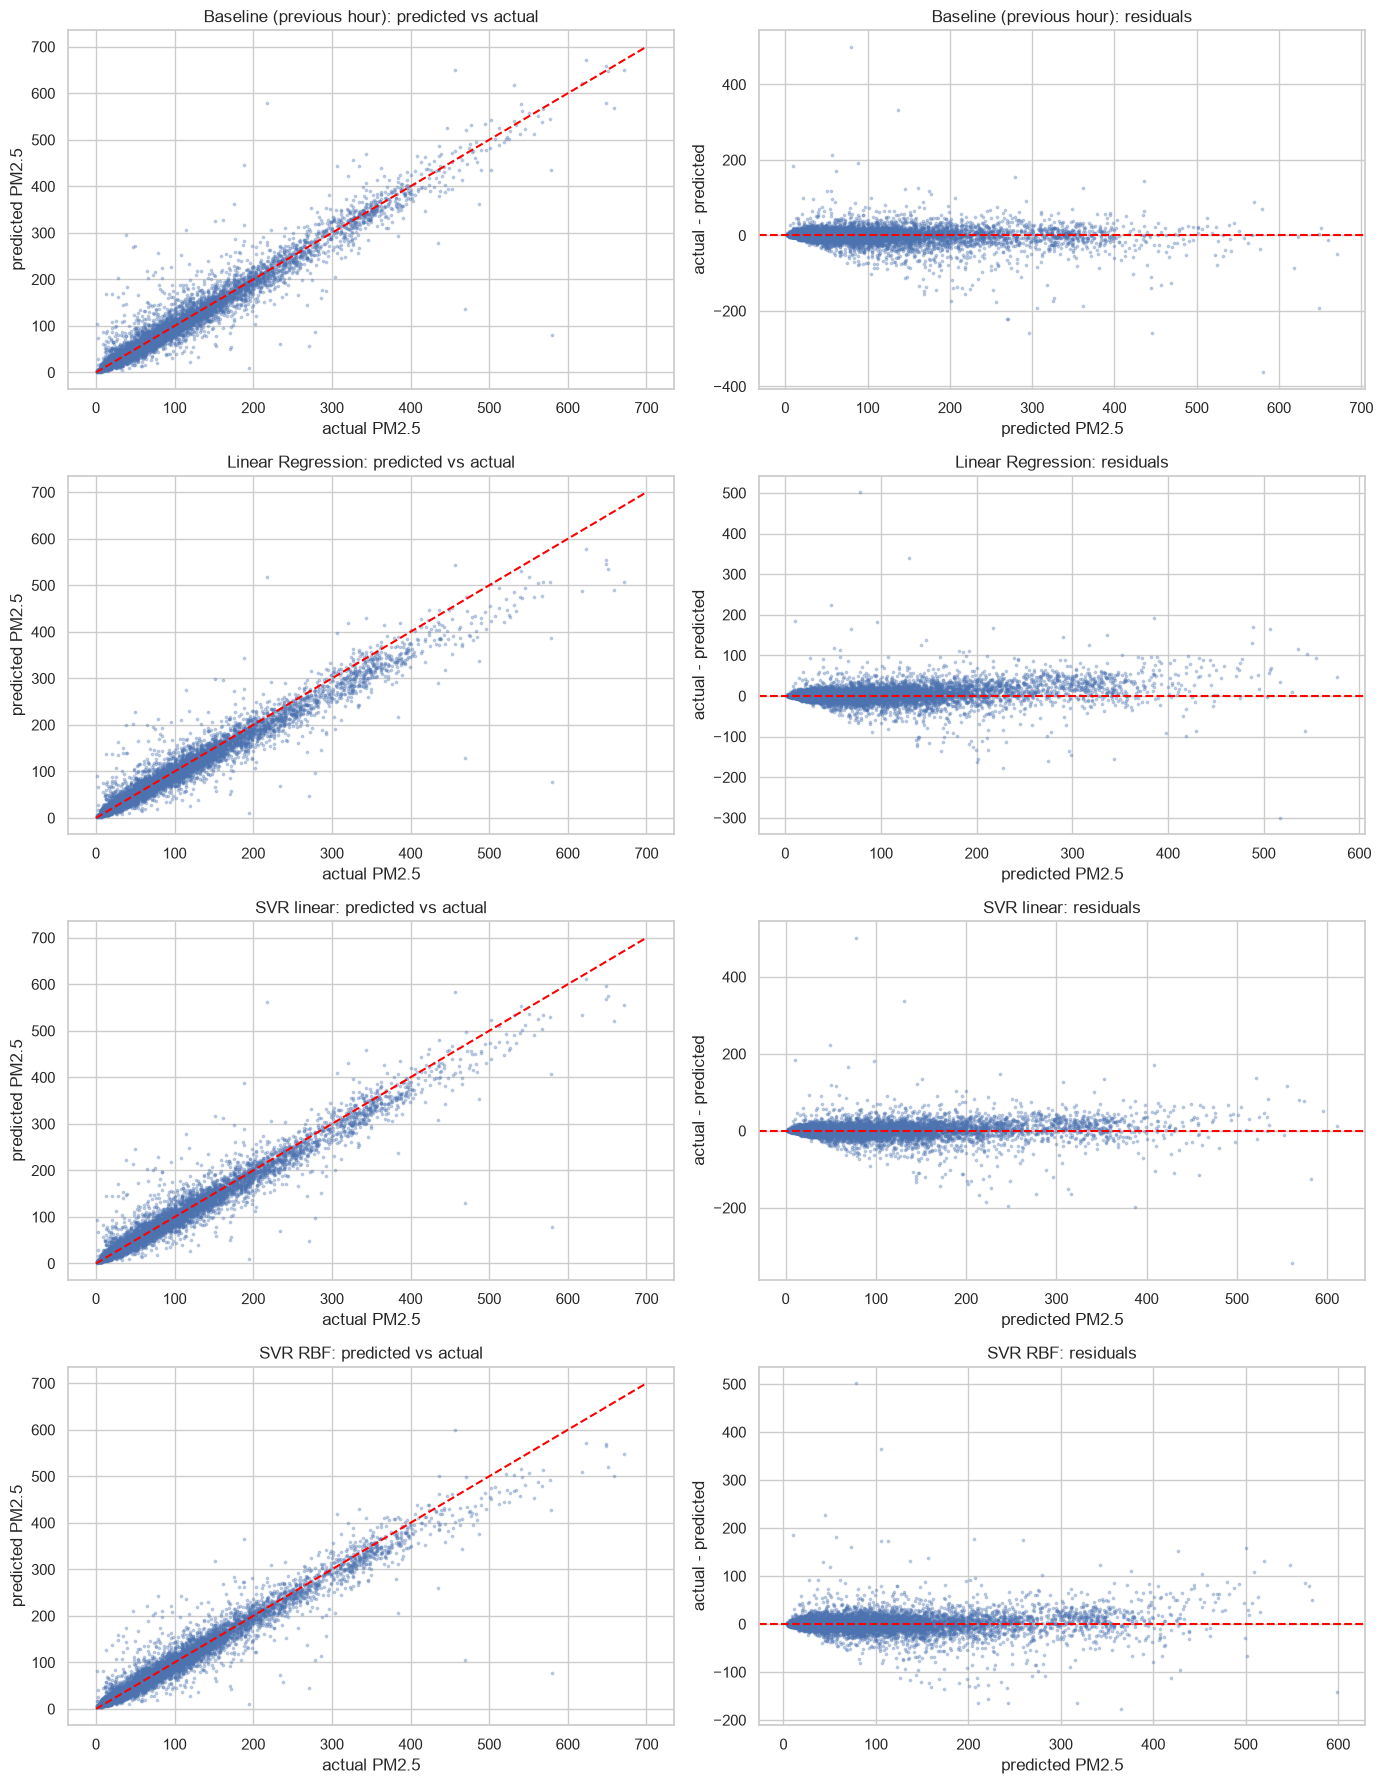

In [120]:
# Predicted vs actual (left) and residuals vs predicted (right) for each model on the 2014 test set
test_preds = {"Baseline (previous hour)": base_test, "Linear Regression": lr_pred_test, **svr_preds}

fig, axes = plt.subplots(len(test_preds), 2, figsize=(14, 4.5 * len(test_preds)))
for row, (name, pred) in zip(axes, test_preds.items()):
    resid = y_test_raw - pred
    row[0].scatter(y_test_raw, pred, s=3, alpha=0.3)
    row[0].plot([0, 700], [0, 700], color="red", ls="--")
    row[0].set_title(f"{name}: predicted vs actual")
    row[0].set_xlabel("actual PM2.5")
    row[0].set_ylabel("predicted PM2.5")
    row[1].scatter(pred, resid, s=3, alpha=0.3)
    row[1].axhline(0, color="red", ls="--")
    row[1].set_title(f"{name}: residuals")
    row[1].set_xlabel("predicted PM2.5")
    row[1].set_ylabel("actual - predicted")
plt.tight_layout()
save(fig, "13_regression_pred_vs_actual_residuals")
plt.show()

### 4.10 Errors by pollution level (extreme spikes)

In [121]:
# How do the models behave on extreme spikes? Errors by PM2.5 level in the test set
levels = pd.cut(y_test_raw, [0, 35.4, 55.4, 150.4, 300, 1000],
                labels=["<=35", "35-55", "55-150", "150-300", ">300"])
spike_rows = []
for name, pred in test_preds.items():
    err = pd.DataFrame({"level": levels, "abs_err": np.abs(y_test_raw - pred), "bias": pred - y_test_raw})
    g = err.groupby("level", observed=True)
    spike_rows.append(pd.concat({"MAE": g["abs_err"].mean(), "mean bias": g["bias"].mean()}, axis=1).assign(model=name))
spike_table = pd.concat(spike_rows).reset_index().pivot(index="level", columns="model")
print("Hours per level in 2014:", levels.value_counts().sort_index().to_dict())
spike_table.round(1)

Hours per level in 2014: {'<=35': 2568, '35-55': 1052, '55-150': 3374, '150-300': 1297, '>300': 469}


MAE                                       \
model   Baseline (previous hour) Linear Regression SVR RBF SVR linear   
level                                                                   
<=35                         5.6               5.3     5.1        5.4   
35-55                        9.9               9.0     8.7        9.2   
55-150                      12.6              11.7    11.6       11.7   
150-300                     19.5              21.8    17.9       19.2   
>300                        23.7              41.1    30.6       29.9   

                       mean bias                                       
model   Baseline (previous hour) Linear Regression SVR RBF SVR linear  
level                                                                  
<=35                         2.0               2.6     2.6        2.6  
35-55                        2.0               2.7     2.0        3.0  
55-150                      -0.1              -1.3     0.3        0.0  
150-300                     -3.4             -14.5    -4.9       -8.6  
>300                        -5.3             -36.9   -21.1      -21.0

### 4.11 Zoom on the worst 2014 smog episode

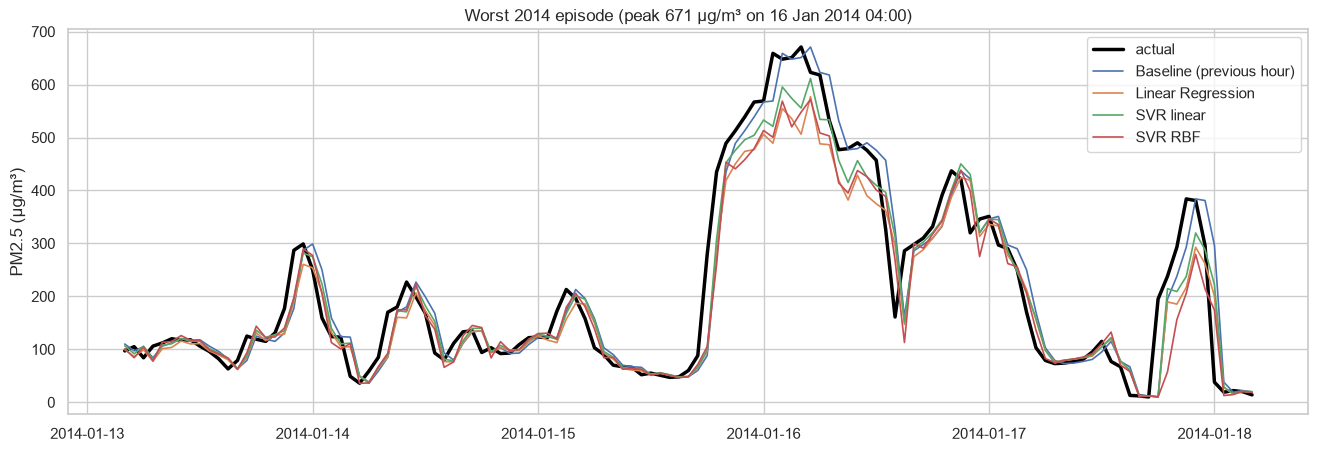

In [122]:
# Zoom into the worst smog episode of 2014 to see how each model follows a spike
peak = y_test_raw.idxmax()
window = slice(peak - pd.Timedelta(days=3), peak + pd.Timedelta(days=2))

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(y_test_raw.loc[window], color="black", lw=2.5, label="actual")
for name, pred in test_preds.items():
    ax.plot(pd.Series(pred, index=y_test_raw.index).loc[window], lw=1.2, label=name)
ax.set_title(f"Worst 2014 episode (peak {y_test_raw.max():.0f} µg/m³ on {peak:%d %b %Y %H:%M})")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
save(fig, "14_regression_spike_zoom")
plt.show()

## Part 4 summary: regression

**Results on the 2014 test set (µg/m³)**

| Model | RMSE test | MAE test | R² test | RMSE train |
|---|---|---|---|---|
| Baseline (previous hour) | 21.91 | 11.82 | 0.945 | 24.65 |
| Linear Regression | 22.14 | 12.59 | 0.944 | 23.84 |
| SVR linear (C=1, ε=0.1) | 20.90 | 11.64 | 0.950 | 23.08 |
| **SVR RBF (C=1, ε=0.05, γ=0.01)** | **20.52** | **11.30** | **0.952** | 22.71 |

**Why these models and metrics**
- **Linear Regression** is the simple, interpretable reference: its coefficients show what drives the prediction (lag 1, lag 2 and the 3 h rolling mean dominate, and rain and SE wind matter after that).
- **SVR** with a **linear** kernel is a robust linear model: its ε-insensitive loss ignores small errors and isn't pulled around by outliers the way squared error is. The **RBF** kernel adds non-linear effects, such as the hour × season interaction seen in the EDA.
- **RMSE** punishes big misses (spikes), **MAE** is the typical error in µg/m³, and **R²** is the share of variance explained. All three are reported in µg/m³ after undoing the log (`expm1`).

**SVR sample and tuning.** SVR's training time grows roughly with n² to n³, so it was tuned on the **last 8,000 training hours** (Feb–Dec 2013). A contiguous block keeps the time order that `TimeSeriesSplit` needs, covers every season, and is the period closest to the test year. `TimeSeriesSplit(4)` always validates on hours *after* the ones it trained on, so tuning never peeks into the future.

**Do the models beat the baseline?** Only just. The "previous hour" baseline is very strong (R² 0.945) because PM2.5 changes slowly. RBF SVR beats it by about 6% in RMSE and 4% in MAE. Linear Regression is slightly **worse** than the baseline on test: the relationship isn't fully linear, and its log-scale predictions under-shoot spikes once converted back to µg/m³.

**Behaviour on spikes (4.10, 4.11).** All models are accurate for clean and moderate hours (MAE 5–12). Above 300 µg/m³ the errors grow and every model **under-predicts** (mean bias −21 for SVR and −37 for Linear Regression). A log-scale model predicts close to the *median*, which is below the mean for skewed data, and no weather feature announces a sudden spike in advance. The zoom on the Jan 2014 episode shows the models following the rise about one hour late, like the baseline, and smoothing the peak.

**Over- or underfitting?** Neither is serious. Train and test errors are close for every model (for example RBF SVR RMSE 22.7 train vs 20.5 test; the test year simply had fewer extreme spikes), so there's no overfitting. The remaining error comes from sudden jumps the features can't foresee, which is a limit of the information available rather than of model capacity.

# 5. Turning the Target into Health-Risk Classes

### 5.1 EPA health-risk classes

In [123]:
# Turn PM2.5 into the 4 EPA health-risk classes (fixed cut points from the brief)
class_bins = [-np.inf, 35.4, 55.4, 150.4, np.inf]
class_names = ["Good/Moderate", "Unhealthy for Sensitive", "Unhealthy", "Very Unhealthy/Hazardous"]

model_df["risk"] = pd.cut(model_df["pm2.5"], bins=class_bins, labels=False).astype(int)
y_train_cls = model_df.loc[X_train.index, "risk"]
y_test_cls = model_df.loc[X_test.index, "risk"]

summary = pd.DataFrame({
    "PM2.5 range": ["<= 35.4", "35.5 - 55.4", "55.5 - 150.4", ">= 150.5"],
    "train hours": y_train_cls.value_counts().sort_index().values,
    "train %": (y_train_cls.value_counts(normalize=True).sort_index() * 100).round(1).values,
    "test hours": y_test_cls.value_counts().sort_index().values,
    "test %": (y_test_cls.value_counts(normalize=True).sort_index() * 100).round(1).values,
}, index=class_names)
summary

,PM2.5 range,train hours,train %,test hours,test %
Good/Moderate,<= 35.4,9603,28.9,2568,29.3
Unhealthy for Sensitive,35.5 - 55.4,4019,12.1,1052,12.0
Unhealthy,55.5 - 150.4,12389,37.3,3374,38.5
Very Unhealthy/Hazardous,>= 150.5,7215,21.7,1766,20.2


### 5.2 Hours per class

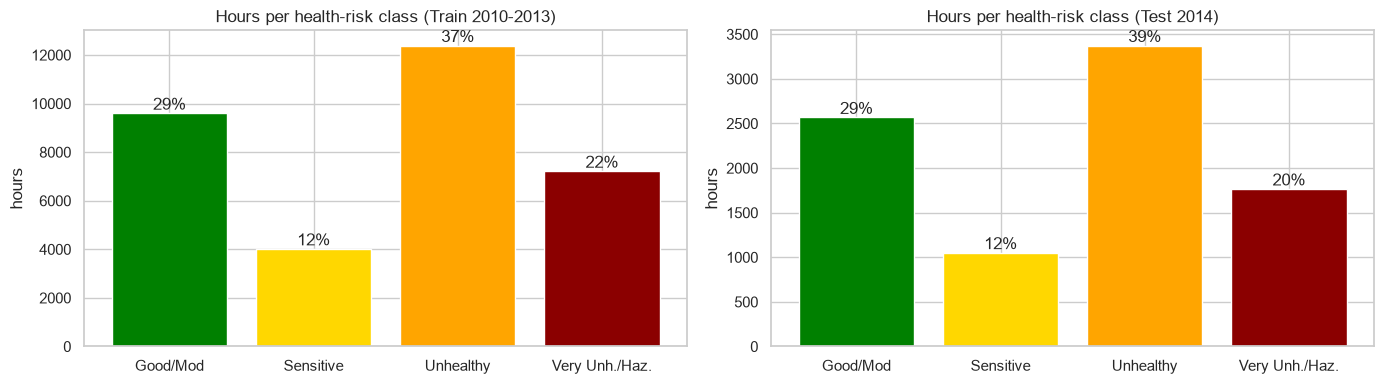

In [124]:
# How many hours fall into each class?
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, y) in zip(axes, [("Train 2010-2013", y_train_cls), ("Test 2014", y_test_cls)]):
    counts = y.value_counts().sort_index()
    ax.bar(range(4), counts, color=["green", "gold", "orange", "darkred"])
    ax.set_xticks(range(4))
    ax.set_xticklabels(["Good/Mod", "Sensitive", "Unhealthy", "Very Unh./Haz."])
    for i, v in enumerate(counts):
        ax.text(i, v, f"{v / len(y):.0%}", ha="center", va="bottom")
    ax.set_title(f"Hours per health-risk class ({name})")
    ax.set_ylabel("hours")
plt.tight_layout()
save(fig, "15_class_distribution")
plt.show()

### 5.3 Why accuracy alone is misleading

In [125]:
# Why accuracy alone misleads: a "model" that always predicts the most common class
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train_cls)
dummy_pred = dummy.predict(X_test)
print("Always predicts:", class_names[dummy_pred[0]])
print(f"Accuracy:          {accuracy_score(y_test_cls, dummy_pred):.2f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test_cls, dummy_pred):.2f}")
print(f"Macro F1:          {f1_score(y_test_cls, dummy_pred, average='macro'):.2f}")

Always predicts: Unhealthy
Accuracy:          0.39
Balanced accuracy: 0.25
Macro F1:          0.14


### 5.4 Removing leaky features (why lags are allowed)

In [126]:
# Features for classification: PM2.5 itself and anything computed from the CURRENT hour's PM2.5 must go.
# Lags/rolling features are kept because they only use earlier hours (shift(1) or more).
leaky = {"pm2.5", "pm25_log", "risk", "was_missing"}
cls_features = [c for c in feature_cols if c not in leaky]
print("Leaky columns in the feature list:", set(feature_cols) & leaky or "none")

# Proof that the lags only look backwards: pm_lag1 at hour t equals the log PM2.5 at hour t-1
t = X_train.index[100]
print(f"pm_lag1 at {t}: {X_train.loc[t, 'pm_lag1']:.4f} | pm25_log at {t - pd.Timedelta(hours=1)}: "
      f"{data.loc[t - pd.Timedelta(hours=1), 'pm25_log']:.4f}")

Leaky columns in the feature list: none
pm_lag1 at 2010-01-07 04:00:00: 3.6376 | pm25_log at 2010-01-07 03:00:00: 3.6376


### 5.5 Oversampling and undersampling (train only)

In [127]:
# Two resampling methods, written by hand with sklearn.utils.resample.
# They are applied ONLY to the training data, after the split, so the test set keeps its real class mix.
from sklearn.utils import resample

def random_oversample(X, y, seed=42):
    """Duplicate random rows of every smaller class until all classes match the biggest one."""
    target = y.value_counts().max()
    parts = [resample(X[y == c], replace=True, n_samples=target, random_state=seed) for c in sorted(y.unique())]
    X_res = pd.concat(parts)
    return X_res, y.loc[X_res.index]

def random_undersample(X, y, seed=42):
    """Drop random rows of every bigger class until all classes match the smallest one."""
    target = y.value_counts().min()
    parts = [resample(X[y == c], replace=False, n_samples=target, random_state=seed) for c in sorted(y.unique())]
    X_res = pd.concat(parts)
    return X_res, y.loc[X_res.index]

X_train_over, y_train_over = random_oversample(X_train[cls_features], y_train_cls)
X_train_under, y_train_under = random_undersample(X_train[cls_features], y_train_cls)

pd.DataFrame({
    "original": y_train_cls.value_counts().sort_index(),
    "oversampled": y_train_over.value_counts().sort_index(),
    "undersampled": y_train_under.value_counts().sort_index(),
}).set_axis(class_names)

,original,oversampled,undersampled
Good/Moderate,9603,12389,4019
Unhealthy for Sensitive,4019,12389,4019
Unhealthy,12389,12389,4019
Very Unhealthy/Hazardous,7215,12389,4019


## Part 5 summary: turning the target into classes

**Class balance.** Using the fixed EPA cut points, the training years split into Good/Moderate 28.9%, Unhealthy for Sensitive Groups **12.1%**, Unhealthy 37.3% and Very Unhealthy/Hazardous 21.7%. The test year (2014) has almost the same mix, so the split is fair. The imbalance is moderate, and the rarest class isn't the most dangerous one. It's the narrow middle band (35.5–55.4), squeezed between two neighbours, which makes it the hardest to recognise.

**Why accuracy alone misleads (5.3).** A "model" that always answers *Unhealthy* already gets **39% accuracy** while being useless: balanced accuracy 0.25 and macro F1 0.14. Accuracy is dominated by the big classes, so a model can score well while never predicting a rare class. That's why we report **balanced accuracy** (the average recall over the classes) and **macro F1** (every class weighs the same), alongside per-class recall and F1.

**Leakage check (5.4).** `pm2.5`, `pm25_log` and the class label are not in the features. The lag and rolling features stay: they only use hours strictly *before* the one being predicted (`shift(1)` or more), which is information an alert system really has at prediction time. The check shows that `pm_lag1` at 04:00 equals the value measured at 03:00.

**Imbalance handling.** Three methods were used, always on the **training data only, after the time split**:
- `class_weight="balanced"`: no rows change, but mistakes on rare classes cost more in the loss.
- **Random oversampling**: rows of the smaller classes are duplicated until every class has 12,389 rows.
- **Random undersampling**: rows of the bigger classes are dropped until every class has 4,019 rows.

Resampling the test set would make it stop looking like reality and inflate the scores. Resampling *before* the split would copy the same hour into both train and test.

# 6. Classification

### 6.1 Classification setup: imports and scoring helper

In [128]:
# Classification imports and one helper that scores every model the same way
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support, roc_curve, auc,
                             precision_recall_curve, average_precision_score)
from sklearn.preprocessing import label_binarize

cls_results = []
cls_models = {}

def score_classifier(name, model, imbalance):
    """Accuracy, balanced accuracy, macro/weighted F1 and per-class recall + F1 on the 2014 test set."""
    pred = model.predict(X_test[cls_features])
    prec, rec, f1, _ = precision_recall_fscore_support(y_test_cls, pred, labels=[0, 1, 2, 3], zero_division=0)
    row = {
        "model": name,
        "imbalance": imbalance,
        "accuracy": accuracy_score(y_test_cls, pred),
        "balanced_acc": balanced_accuracy_score(y_test_cls, pred),
        "macro_F1": f1_score(y_test_cls, pred, average="macro"),
        "weighted_F1": f1_score(y_test_cls, pred, average="weighted"),
    }
    for k, short in enumerate(["Good", "Sensitive", "Unhealthy", "VeryUnh"]):
        row[f"recall_{short}"] = rec[k]
        row[f"F1_{short}"] = f1[k]
    cls_results.append(row)
    cls_models[(name, imbalance)] = model
    return row

tscv_cls = TimeSeriesSplit(n_splits=5)

### 6.2 Tuning Logistic Regression

In [129]:
# Tune Logistic Regression (C and class_weight) with TimeSeriesSplit on the full training set.
# Scoring = macro F1, so every class counts equally, not just the big ones.
logreg_search = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=3000))]),
    param_grid={"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]},
    cv=tscv_cls, scoring="f1_macro", n_jobs=-1,
)
t0 = time.time()
logreg_search.fit(X_train[cls_features], y_train_cls)
print(f"Logistic Regression tuned in {time.time() - t0:.0f}s")
print("Best params:", logreg_search.best_params_)

pd.DataFrame(logreg_search.cv_results_)[["param_model__C", "param_model__class_weight", "mean_test_score"]] \
    .rename(columns={"mean_test_score": "CV macro F1"}).sort_values("CV macro F1", ascending=False)

Logistic Regression tuned in 1s
Best params: {'model__C': 10, 'model__class_weight': 'balanced'}


,param_model__C,param_model__class_weight,CV macro F1
7,10.00,balanced,0.808630
5,1.00,balanced,0.808550
3,0.10,balanced,0.806896
6,10.00,NaN,0.803085
4,1.00,NaN,0.802800
2,0.10,NaN,0.798678
1,0.01,balanced,0.792491
0,0.01,NaN,0.744509


### 6.3 Logistic Regression with 4 imbalance strategies

In [130]:
# Logistic Regression with the best C, trained 4 ways: no handling, class weights, oversampling, undersampling
best_C = logreg_search.best_params_["model__C"]
logreg = lambda cw=None: Pipeline([("prep", preprocessor),
                                   ("model", LogisticRegression(C=best_C, class_weight=cw, max_iter=3000))])

score_classifier("Logistic Regression", clone(logreg()).fit(X_train[cls_features], y_train_cls), "none")
score_classifier("Logistic Regression", clone(logreg("balanced")).fit(X_train[cls_features], y_train_cls), "class_weight")
score_classifier("Logistic Regression", clone(logreg()).fit(X_train_over, y_train_over), "oversampling")
score_classifier("Logistic Regression", clone(logreg()).fit(X_train_under, y_train_under), "undersampling")

pd.DataFrame(cls_results).set_index(["model", "imbalance"]).iloc[:, :4].round(3)

accuracy  balanced_acc  macro_F1  \
model               imbalance                                         
Logistic Regression none              0.858         0.805     0.812   
                    class_weight      0.837         0.849     0.818   
                    oversampling      0.838         0.849     0.819   
                    undersampling     0.834         0.847     0.815   

                                   weighted_F1  
model               imbalance                   
Logistic Regression none                 0.855  
                    class_weight         0.846  
                    oversampling         0.847  
                    undersampling        0.844

### 6.4 Tuning SVC with a linear kernel

In [131]:
# SVC is slow on large data, so (like SVR) tune it on the last 8,000 training hours.
X_svc = X_train[cls_features].iloc[-N_SAMPLE:]
y_svc = y_train_cls.iloc[-N_SAMPLE:]
print("SVC sample classes:", y_svc.value_counts().sort_index().to_dict())

svc_lin_search = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", SVC(kernel="linear"))]),
    param_grid={"model__C": [0.01, 0.1, 1], "model__class_weight": [None, "balanced"]},
    cv=TimeSeriesSplit(n_splits=4), scoring="f1_macro", n_jobs=-1,
)
t0 = time.time()
svc_lin_search.fit(X_svc, y_svc)
print(f"Linear SVC tuned in {time.time() - t0:.0f}s | best:", svc_lin_search.best_params_,
      f"| CV macro F1 {svc_lin_search.best_score_:.3f}")

SVC sample classes: {0: 2245, 1: 1063, 2: 3161, 3: 1531}
Linear SVC tuned in 1s | best: {'model__C': 1, 'model__class_weight': 'balanced'} | CV macro F1 0.772


### 6.5 Tuning SVC with an RBF kernel

In [132]:
# RBF SVC: tune C, gamma and class_weight
svc_rbf_search = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", SVC(kernel="rbf"))]),
    param_grid={"model__C": [0.3, 1, 3, 10], "model__gamma": ["scale", 0.01, 0.03],
                "model__class_weight": [None, "balanced"]},
    cv=TimeSeriesSplit(n_splits=4), scoring="f1_macro", n_jobs=-1,
)
t0 = time.time()
svc_rbf_search.fit(X_svc, y_svc)
print(f"RBF SVC tuned in {time.time() - t0:.0f}s | best:", svc_rbf_search.best_params_,
      f"| CV macro F1 {svc_rbf_search.best_score_:.3f}")

RBF SVC tuned in 3s | best: {'model__C': 3, 'model__class_weight': 'balanced', 'model__gamma': 0.01} | CV macro F1 0.768


### 6.6 Evaluating the SVCs and the full comparison table

In [133]:
# Refit both SVCs with and without class weights (other params = tuned) and score them on 2014
for kernel, search in [("SVC linear", svc_lin_search), ("SVC RBF", svc_rbf_search)]:
    for cw, label in [(None, "none"), ("balanced", "class_weight")]:
        model = clone(search.best_estimator_).set_params(model__class_weight=cw).fit(X_svc, y_svc)
        score_classifier(kernel, model, label)

cls_table = pd.DataFrame(cls_results).set_index(["model", "imbalance"])
cls_table.round(3).to_csv("results/classification_results.csv")
cls_table[["accuracy", "balanced_acc", "macro_F1", "weighted_F1",
           "recall_Sensitive", "recall_VeryUnh"]].round(3)

accuracy  balanced_acc  macro_F1  \
model               imbalance                                         
Logistic Regression none              0.858         0.805     0.812   
                    class_weight      0.837         0.849     0.818   
                    oversampling      0.838         0.849     0.819   
                    undersampling     0.834         0.847     0.815   
SVC linear          none              0.859         0.818     0.821   
                    class_weight      0.831         0.843     0.812   
SVC RBF             none              0.858         0.813     0.817   
                    class_weight      0.833         0.844     0.813   

                                   weighted_F1  recall_Sensitive  \
model               imbalance                                      
Logistic Regression none                 0.855             0.500   
                    class_weight         0.846             0.836   
                    oversampling         0.847             0.831   
                    undersampling        0.844             0.834   
SVC linear          none                 0.858             0.569   
                    class_weight         0.840             0.821   
SVC RBF             none                 0.856             0.555   
                    class_weight         0.841             0.814   

                                   recall_VeryUnh  
model               imbalance                      
Logistic Regression none                    0.902  
                    class_weight            0.937  
                    oversampling            0.939  
                    undersampling           0.937  
SVC linear          none                    0.910  
                    class_weight            0.947  
SVC RBF             none                    0.895  
                    class_weight            0.947

### 6.7 Confusion matrices

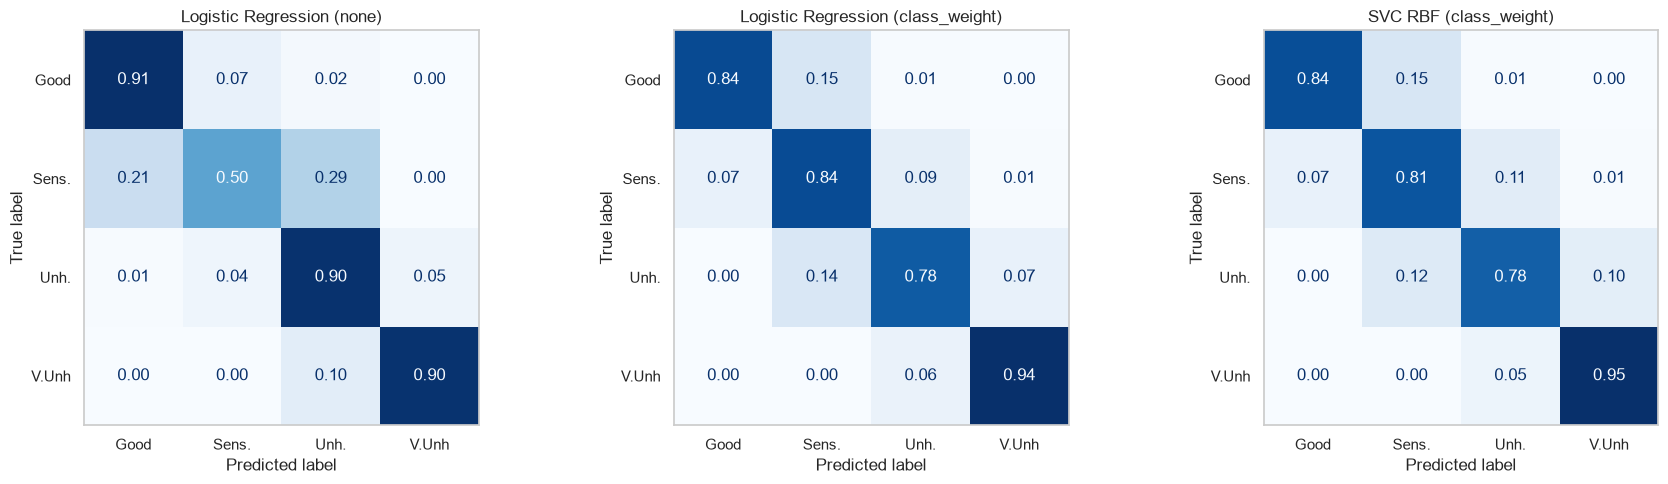

In [134]:
# Confusion matrices (rows = true class, normalized so each row sums to 1 = recall per class)
to_show = [("Logistic Regression", "none"), ("Logistic Regression", "class_weight"),
           ("SVC RBF", "class_weight")]
short_names = ["Good", "Sens.", "Unh.", "V.Unh"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, key in zip(axes, to_show):
    ConfusionMatrixDisplay.from_estimator(cls_models[key], X_test[cls_features], y_test_cls,
                                          display_labels=short_names, normalize="true",
                                          values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{key[0]} ({key[1]})")
    ax.grid(False)
plt.tight_layout()
save(fig, "16_confusion_matrices")
plt.show()

### 6.8 Per-class classification report

In [135]:
# Full per-class report for the class-weighted Logistic Regression
best_cls = cls_models[("Logistic Regression", "class_weight")]
print(classification_report(y_test_cls, best_cls.predict(X_test[cls_features]),
                            target_names=class_names, digits=3))

                          precision    recall  f1-score   support

           Good/Moderate      0.963     0.840     0.897      2568
 Unhealthy for Sensitive      0.500     0.836     0.626      1052
               Unhealthy      0.925     0.782     0.847      3374
Very Unhealthy/Hazardous      0.866     0.937     0.900      1766

                accuracy                          0.837      8760
               macro avg      0.814     0.849     0.818      8760
            weighted avg      0.873     0.837     0.846      8760



### 6.10 With vs without imbalance handling

In [137]:
# With vs without imbalance handling: how did the rare classes change?
lr_rows = cls_table.loc["Logistic Regression"]
cols = ["recall_Sensitive", "F1_Sensitive", "recall_VeryUnh", "F1_VeryUnh", "balanced_acc", "macro_F1", "accuracy"]
change = lr_rows[cols].copy()
change.loc["class_weight - none"] = lr_rows.loc["class_weight", cols] - lr_rows.loc["none", cols]
change.loc["oversampling - none"] = lr_rows.loc["oversampling", cols] - lr_rows.loc["none", cols]
change.loc["undersampling - none"] = lr_rows.loc["undersampling", cols] - lr_rows.loc["none", cols]
change.round(3)

,recall_Sensitive,F1_Sensitive,recall_VeryUnh,F1_VeryUnh,balanced_acc,macro_F1,accuracy
imbalance,,,,,,,
none,0.500,0.554,0.902,0.905,0.805,0.812,0.858
class_weight,0.836,0.626,0.937,0.900,0.849,0.818,0.837
oversampling,0.831,0.627,0.939,0.901,0.849,0.819,0.838
undersampling,0.834,0.622,0.937,0.899,0.847,0.815,0.834
class_weight - none,0.336,0.072,0.035,-0.004,0.043,0.006,-0.022
oversampling - none,0.331,0.073,0.037,-0.003,0.044,0.007,-0.020
undersampling - none,0.334,0.068,0.035,-0.005,0.041,0.003,-0.024


### 6.11 (Optional) Binary hazardous alert and decision thresholds

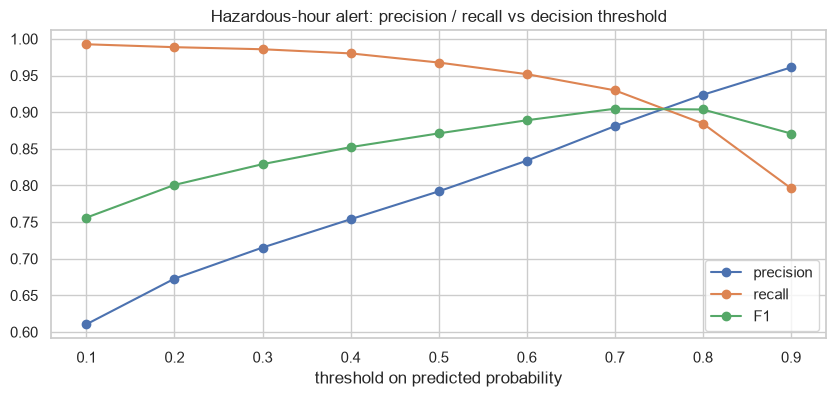

Hazardous hours in 2014: 1766 of 8760


,precision,recall,F1,missed hazardous hours,false alarms
threshold,,,,,
0.1,0.611,0.993,0.756,13,1118
0.2,0.673,0.989,0.801,20,849
0.3,0.715,0.986,0.829,25,693
0.4,0.754,0.980,0.852,35,565
0.5,0.792,0.968,0.871,57,449
0.6,0.834,0.952,0.889,85,335
0.7,0.881,0.930,0.905,124,222
0.8,0.924,0.884,0.904,204,129
0.9,0.961,0.796,0.871,360,57


: 

In [ ]:
# Optional: binary "Very Unhealthy/Hazardous vs not" alert, and the effect of the decision threshold
y_train_haz = (y_train_cls == 3).astype(int)
y_test_haz = (y_test_cls == 3).astype(int)

haz_model = Pipeline([("prep", preprocessor),
                      ("model", LogisticRegression(C=best_C, class_weight="balanced", max_iter=3000))])
haz_model.fit(X_train[cls_features], y_train_haz)
haz_prob = haz_model.predict_proba(X_test[cls_features])[:, 1]

rows = []
for thr in np.arange(0.1, 0.95, 0.1):
    pred = (haz_prob >= thr).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_test_haz, pred, average="binary", zero_division=0)
    rows.append({"threshold": round(thr, 1), "precision": p, "recall": r, "F1": f,
                 "missed hazardous hours": int(((pred == 0) & (y_test_haz == 1)).sum()),
                 "false alarms": int(((pred == 1) & (y_test_haz == 0)).sum())})
thr_table = pd.DataFrame(rows).set_index("threshold")

fig, ax = plt.subplots(figsize=(10, 4))
thr_table[["precision", "recall", "F1"]].plot(ax=ax, marker="o")
ax.set_title("Hazardous-hour alert: precision / recall vs decision threshold")
ax.set_xlabel("threshold on predicted probability")
save(fig, "18_threshold_tradeoff")
plt.show()

print(f"Hazardous hours in 2014: {y_test_haz.sum()} of {len(y_test_haz)}")
thr_table.round(3)

## Part 6 summary: classification

**Results on the 2014 test set**

| Model | Imbalance | Accuracy | Balanced acc. | Macro F1 | Weighted F1 | Recall *Sensitive* | Recall *Very Unh.* |
|---|---|---|---|---|---|---|---|
| Logistic Regression (C=10) | none | 0.858 | 0.805 | 0.812 | 0.855 | 0.500 | 0.902 |
| Logistic Regression | class_weight | 0.837 | 0.849 | 0.818 | 0.846 | 0.836 | 0.937 |
| Logistic Regression | oversampling | 0.838 | 0.849 | **0.819** | 0.847 | 0.831 | 0.939 |
| Logistic Regression | undersampling | 0.834 | 0.847 | 0.815 | 0.844 | 0.834 | 0.937 |
| SVC linear (C=1) | none | **0.859** | 0.818 | **0.821** | **0.858** | 0.569 | 0.910 |
| SVC linear | class_weight | 0.831 | 0.843 | 0.812 | 0.840 | 0.821 | **0.947** |
| SVC RBF (C=3, γ=0.01) | none | 0.858 | 0.813 | 0.817 | 0.856 | 0.555 | 0.895 |
| SVC RBF | class_weight | 0.833 | 0.844 | 0.813 | 0.841 | 0.814 | **0.947** |

**Why these models and metrics.** **Logistic Regression** is fast, gives real probabilities (needed for ROC/PR curves and thresholds), and is easy to explain. **SVC** with a linear kernel finds a maximum-margin boundary, and the **RBF** kernel can bend the boundary for non-linear patterns. Both were tuned with `TimeSeriesSplit` using **macro F1** as the score, so the rare classes count as much as the common ones. SVC was tuned and trained on the last 8,000 training hours for speed, so it saw less data than Logistic Regression.

**What the results show**
- All models land close together (macro F1 0.81–0.82), because the lag features carry most of the information. The RBF kernel doesn't beat the linear models here.
- **Confusion matrices (6.7):** almost all mistakes are between **neighbouring** classes (for example Sensitive ↔ Good or Sensitive ↔ Unhealthy). A Good hour is essentially never called Very Unhealthy, and vice versa.
- **ROC / PR curves (6.9):** the extreme classes are easy (ROC AUC 0.99, average precision 0.96–0.97). The *Sensitive* band is the hard one (AUC 0.93 and AP 0.57 for Logistic Regression). Its PR curve sits far below the others, because a narrow band between two neighbours is easy to confuse with both.

**With vs without imbalance handling (6.10, Logistic Regression)**
- *Sensitive* recall jumped from **0.50 to 0.84 (+0.34)** with class weights, and similarly with over- or undersampling. Its F1 rose from 0.55 to 0.63 (+0.07).
- *Very Unhealthy/Hazardous* recall rose from **0.90 to 0.94 (+0.035)**. Out of 1,766 dangerous hours, about 60 more are caught.
- Balanced accuracy rose from 0.805 to 0.849 (+0.04), while plain **accuracy fell** from 0.858 to 0.837 (−0.02). The model now predicts the rare classes more often, which trades some precision on the big classes for recall on the small ones.
- The three methods give almost identical results. Class weights are the simplest: no duplicated or discarded rows, and nothing extra to fit.

**Health alerts: missed hazard or false alarm?** Missing a hazardous hour is worse. A false alarm costs some inconvenience (people stay inside or wear a mask), but a missed alarm exposes children, the elderly and people with asthma or heart disease to dangerous air without warning. The metric that matters most is therefore **recall on the Very Unhealthy/Hazardous class**, while keeping precision acceptable so people don't start ignoring alerts. F2 or recall at a fixed precision are good ways to express that.

**Binary alert and thresholds (6.11).** A *Hazardous vs not* Logistic Regression shows the trade-off directly. At the default 0.5 threshold it catches 96.8% of the 1,766 hazardous hours (57 missed) with 449 false alarms. Lowering the threshold to **0.3** misses only **25** hours (recall 98.6%) at the cost of 693 false alarms (precision 0.72). Raising it to 0.8 cuts false alarms to 129 but misses 204 hazardous hours. For a health alert, a low threshold (about 0.3) is the better choice.

# 7. Conclusions

**Data.** 5 years of hourly Beijing PM2.5 and weather. After cleaning (interpolating gaps of 24 h or less, dropping longer gaps, fixing a frozen weather sensor and impossible values), 96.9% of the rows were kept. The extreme spikes turned out to be real events (Chinese New Year fireworks, winter smog episodes), so they were kept.

**What drives pollution.** Its own recent past (lag-1 autocorrelation 0.965), calm or southern wind vs cleansing north-west wind, humid near-saturated air (dew-point spread, Spearman −0.52), night-time, and the heating season.

**Regression.** Predicting the log of PM2.5 with a tuned RBF SVR gives RMSE 20.5 µg/m³ and R² 0.95 on 2014, about 6% better than the strong "previous hour" baseline. Every model under-predicts the most extreme spikes and reacts about an hour late.

**Classification.** Across the 4 EPA classes, all tuned models reach macro F1 of about 0.82. Handling the class imbalance (class weights, over- or undersampling) raised recall on the rare *Sensitive Groups* class from 0.50 to 0.84 and on *Very Unhealthy/Hazardous* from 0.90 to 0.94, at the cost of about 2 points of accuracy. For a health alert, recall on the hazardous class matters most. A binary hazardous-hour model with a 0.3 threshold catches 98.6% of hazardous hours.

**Limitations and next steps**
- The models mostly extend the recent past. Forecasts further ahead (6–24 h) would need weather *forecasts* as inputs.
- SVR and SVC were trained on an 8,000-hour sample for speed. Tree ensembles (Random Forest, gradient boosting) could use all the data and capture non-linear effects without scaling.
- A bias correction for the log back-transform, or a quantile/weighted loss, could reduce the under-prediction of spikes.